# 04 · Robustez del ángulo de Cobb frente al grosor de corte

## Propósito

`compute-Cobb-angle.py` mide el ángulo en una proyección coronal reconstruida a partir de resonancias sagitales. En esas secuencias, el eje lateral (derecha–izquierda) es el de menor resolución: entre un corte sagital y el siguiente hay entre 3 y 5 mm en las series estándar de SPIDER, frente a 0,9 mm en las T2 SPACE. Este cuaderno pregunta cuánto depende el ángulo de ese grosor de corte.

La pregunta se aborda por tres caminos, ordenados de menor a mayor capacidad de atribuir el efecto al grosor:

- **Descripción por grosor y grupo de adquisición:** el ángulo de las máscaras únicas agrupado por grosor de corte y por escáner o centro. En SPIDER el grosor está confundido con el protocolo de adquisición, así que esta parte solo describe.
- **Comparación dentro del mismo paciente:** en los estudios con T2 SPACE, el ángulo de la serie fina frente al de las series estándar del mismo paciente. Es la misma columna, pero con otra secuencia y otra segmentación manual.
- **Experimento de engrosamiento:** cada una de las 41 máscaras T2 SPACE se convierte en una máscara de cortes de 3,3 y 4,4 mm, con dos métodos y tres posiciones del primer corte, y se vuelve a calcular el ángulo. Como se parte de la misma máscara, la diferencia sí puede atribuirse al grosor y a la posición de los cortes.

## Alcance

Este es un análisis técnico y descriptivo con máscaras de segmentación de datos públicos. Su objetivo es documentar cuánto depende la salida del algoritmo del grosor de corte. No constituye una validación clínica ni está destinado al diagnóstico de escoliosis. Los cortes gruesos se simulan sobre la máscara, no sobre la imagen, así que el experimento no reproduce cómo segmentaría un especialista una serie gruesa real.

## Fuentes

- **Algoritmo:** [DIAGNijmegen/cobb-angle-algorithm](https://github.com/DIAGNijmegen/cobb-angle-algorithm), commit `72c712f31e1f3069aef77b98b20af448bbc5615a`.
- **Dependencia:** [DIAGNijmegen/Tiger](https://github.com/DIAGNijmegen/Tiger), commit `4c63f6d58ed3f8e7a0cec04b0352949f7b512919`.
- **Método publicado:** van der Graaf *et al.*, *European Radiology* (2024), [artículo completo](https://pmc.ncbi.nlm.nih.gov/articles/PMC11364572/).
- **Datos:** [SPIDER v4](https://doi.org/10.5281/zenodo.10159290), licencia CC BY 4.0.

## Antes de ejecutar: datos necesarios

Este cuaderno utiliza las máscaras de SPIDER v4 preparadas en el cuaderno 01 y los resultados de los cuadernos 01 y 03. No descarga automáticamente el conjunto de datos.

Los archivos de entrada son:

| Archivo | Ruta en Google Drive | Obligatorio |
|---|---|---|
| `masks.zip` | `MyDrive/PRL/content/datos/spider/masks/masks.zip` | Sí |
| `inventario_series.csv` | `MyDrive/PRL/salidas/resultados_semana1/01_INVENTARIO_SPIDER/inventario_series.csv` | Sí |
| `angulos_variantes.csv` | `MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/angulos_variantes.csv` | Sí |

Los resultados se guardan en:

`MyDrive/PRL/salidas/resultados_semana2/04_robustez_grosor_de_corte/`

El experimento corre el script unas 530 veces, a razón de unos 20 s por corrida, es decir, cerca de tres horas en Colab. El procesamiento se hace corrida por corrida: si Colab se interrumpe, basta con volver a ejecutar las celdas de configuración y la de procesamiento, y el registro de las corridas ya hechas permite continuar con las pendientes.

In [21]:
# 1. Dependencias: Tiger fijado al commit verificado (no a la rama, que puede moverse)
!pip -q install "git+https://github.com/DIAGNijmegen/Tiger.git@4c63f6d58ed3f8e7a0cec04b0352949f7b512919" SimpleITK==2.5.6

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [22]:
# 2. Configuración
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
DIR_SPIDER = DIR_PRL / "content" / "datos" / "spider"
DIR_SCRIPT = DIR_PRL / "content" / "datos" / "compute-Cobb-angle"
CSV_INVENTARIO = DIR_PRL / "salidas" / "resultados_semana1" / "01_INVENTARIO_SPIDER" / "inventario_series.csv"
CSV_VARIANTES_03 = DIR_PRL / "salidas" / "resultados_semana2" / "03_disco_caudal_y_variantes" / "angulos_variantes.csv"
DIR_SALIDA = DIR_PRL / "salidas" / "resultados_semana2" / "04_robustez_grosor_de_corte"
DIR_EXTREMOS = DIR_SALIDA / "casos_extremos"
DIR_LOCAL = Path("/content/mascaras_space")        # copia local de las T2 SPACE
DIR_GRUESAS = Path("/content/mascaras_engrosadas")  # máscaras engrosadas temporales (no se guardan en Drive)

COMMIT_SCRIPT = "72c712f31e1f3069aef77b98b20af448bbc5615a"
COMMIT_TIGER = "4c63f6d58ed3f8e7a0cec04b0352949f7b512919"
SHA256_SCRIPT = "4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849"   # verificado el 1, el 15 y el 16-oct-2026
MD5_MASKS_ZIP = "49861ff25a0108b3b69d0ce808ae51dc"   # descarga verificada contra Zenodo el 2-oct-2026
N_ESPERADO = 447                                      # series de SPIDER según el cuaderno 01
N_SPACE = 41                                          # series T2 SPACE según el cuaderno 01
DISCO_CAUDAL = 201                                    # etiqueta SPIDER del disco más caudal

GROSORES_MM = (3.3, 4.4)              # grosores de las series estándar de SPIDER que se simulan
METODOS = ("vecino", "mayoritaria")   # ver la definición del experimento
DESFASES = (0, 1/3, 2/3)              # posición del primer corte grueso, en fracciones del grosor

for d in (DIR_SALIDA, DIR_EXTREMOS, DIR_SCRIPT, DIR_LOCAL, DIR_GRUESAS):
    d.mkdir(parents=True, exist_ok=True)
for archivo in (CSV_INVENTARIO, CSV_VARIANTES_03):
    assert archivo.exists(), f"Falta {archivo}: corre antes el cuaderno que lo genera"
print("Salida:", DIR_SALIDA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Salida: /content/drive/MyDrive/PRL/salidas/resultados_semana2/04_robustez_grosor_de_corte


## Script fijado y verificado

Para que el experimento sea reproducible, la celda 3 descarga `compute-Cobb-angle.py` desde un commit concreto y comprueba su huella SHA-256 antes de usarlo. Si la huella no coincide, el cuaderno se detiene.

Al script se le agrega una sola línea en la función `PCA()`, que toma la parte real del resultado de `np.linalg.eig` para que funcione con NumPy 2; las rutas de entrada y salida se ajustan a Colab al ejecutarlo. En el cuaderno 02, esta adaptación se contrastó con la versión original ejecutada con NumPy 1.26 en cinco máscaras, y los ángulos coincidieron hasta la decimotercera cifra decimal.

In [23]:
# 3. Descargar el script del commit fijado, verificarlo y preparar la versión ejecutable
import hashlib, requests

def sha256_de(datos: bytes) -> str:
    return hashlib.sha256(datos).hexdigest()

url = f"https://raw.githubusercontent.com/DIAGNijmegen/cobb-angle-algorithm/{COMMIT_SCRIPT}/compute-Cobb-angle.py"
original = requests.get(url, timeout=60).content
sha_obtenido = sha256_de(original)
print("SHA-256 obtenido:", sha_obtenido)
assert sha_obtenido == SHA256_SCRIPT, "El script descargado NO coincide con el verificado; no continuar."

texto = original.decode("utf-8")
LINEA_EIG = "    eigenvalues, eigenvectors = np.linalg.eig(matrix)\n"
PARCHE = "    eigenvalues, eigenvectors = eigenvalues.real, eigenvectors.real  # adaptación a NumPy 2 (ver cuaderno 02)\n"
assert texto.count(LINEA_EIG) == 1
codigo = texto.replace(LINEA_EIG, LINEA_EIG + PARCHE)
print("Script listo con la adaptación a NumPy 2")

SHA-256 obtenido: 4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849
Script listo con la adaptación a NumPy 2


## Máscaras: verificación y copia local

Se comprueba que `masks.zip` conserva la huella MD5 verificada contra Zenodo, y las 41 máscaras T2 SPACE se copian desde ese archivo a una carpeta local de Colab. Como la copia sale del zip verificado, la entrada es la de SPIDER v4 sin alteraciones. Las demás máscaras no se necesitan: las partes de descripción y de comparación dentro del paciente usan los ángulos que ya calculó el cuaderno 03.

Estas verificaciones comprueban la integridad de los archivos de entrada, pero no evalúan la exactitud anatómica de las segmentaciones.

In [24]:
# 4. Verificar masks.zip y copiar las máscaras T2 SPACE a disco local
import zipfile

def md5_archivo(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

zip_masks = next((p for p in (DIR_SPIDER / "masks.zip", DIR_SPIDER / "masks" / "masks.zip") if p.exists()), None)
assert zip_masks is not None, "No encontré masks.zip en datos/spider ni en datos/spider/masks"
md5_zip = md5_archivo(zip_masks)
print("MD5 de masks.zip:", md5_zip, "| coincide con la verificada:", md5_zip == MD5_MASKS_ZIP)
assert md5_zip == MD5_MASKS_ZIP

with zipfile.ZipFile(zip_masks) as z:
    miembros = {Path(n).name: n for n in z.namelist() if n.endswith(".mha")}
    assert len(miembros) == N_ESPERADO, f"Se esperaban {N_ESPERADO} máscaras en el zip y hay {len(miembros)}"
    for nombre, miembro in miembros.items():
        if "space" in nombre.lower():
            (DIR_LOCAL / nombre).write_bytes(z.read(miembro))

mascaras = sorted(DIR_LOCAL.glob("*.mha"))
print(f"{len(miembros)} máscaras en el zip | {len(mascaras)} T2 SPACE copiadas a {DIR_LOCAL}")
assert len(mascaras) == N_SPACE, f"Se esperaban {N_SPACE} máscaras T2 SPACE y hay {len(mascaras)}"

MD5 de masks.zip: 49861ff25a0108b3b69d0ce808ae51dc | coincide con la verificada: True
447 máscaras en el zip | 41 T2 SPACE copiadas a /content/mascaras_space


## Ángulos y metadatos de cada serie

La celda 5 une los ángulos del cuaderno 03 (el original del script y las variantes A, B y AB) con el inventario del cuaderno 01, que trae el espaciado entre cortes laterales, el escáner y el centro inferido de cada serie. Como en el cuaderno 03, la columna `mascara_unica` marca la primera aparición de cada máscara, porque 107 parejas T1/T2 del mismo estudio comparten exactamente la misma máscara y contarlas dos veces inflaría los conteos.

El escáner se toma de los metadatos DICOM que publica SPIDER (fabricante, modelo e intensidad de campo). El centro no viene en el conjunto de datos: el inventario solo puede inferir el centro universitario, porque es el único que adquirió T2 SPACE, y al resto de los estudios los agrupa por su escáner. Esa agrupación, que aquí se llama `grupo_adquisicion`, es la que mejor separa los protocolos y la que se usa en la descripción.

In [25]:
# 5. Unir los ángulos del cuaderno 03 con el inventario
import numpy as np, pandas as pd
inventario = pd.read_csv(CSV_INVENTARIO, dtype={"serie": str})
var03 = pd.read_csv(CSV_VARIANTES_03, dtype={"serie": str})
series = var03.merge(inventario[["serie", "escaner", "centro_proxy", "espaciado_lr_mm", "grosor_lr_rango", "sexo"]],
                     on="serie", how="left", validate="one_to_one")
assert len(series) == N_ESPERADO and series["espaciado_lr_mm"].notna().all(), "No se unieron todas las series con el inventario"
series["grupo_adquisicion"] = series["centro_proxy"].str.replace("otro: ", "", regex=False)
ORDEN_GROSOR = ["<1 mm", "3–4 mm", "4–5 mm", "≥5 mm"]
unicas = series[series["mascara_unica"]]
print(f"{len(series)} series · {len(unicas)} máscaras únicas\n")
print("Máscaras únicas por modelo de escáner y grosor de corte lateral:")
print(pd.crosstab(unicas["escaner"], unicas["grosor_lr_rango"]).reindex(columns=ORDEN_GROSOR, fill_value=0).to_string())
print("\nMáscaras únicas por grupo de adquisición (centro inferido o escáner) y grosor de corte lateral:")
print(pd.crosstab(unicas["grupo_adquisicion"], unicas["grosor_lr_rango"]).reindex(columns=ORDEN_GROSOR, fill_value=0).to_string())

447 series · 340 máscaras únicas

Máscaras únicas por modelo de escáner y grosor de corte lateral:
grosor_lr_rango                            <1 mm  3–4 mm  4–5 mm  ≥5 mm
escaner                                                                
Philips Healthcare | Ingenia | 3.0 T           0      97       0      0
Philips Medical Systems | Ingenia | 1.5 T      0       0      28      0
Philips Medical Systems | Ingenia | 3.0 T      0       0       1      0
SIEMENS | Aera | 1.5 T                         0       0      32      1
SIEMENS | Avanto | 1.5 T                       0       0       2      0
SIEMENS | Avanto_fit | 1.5 T                  40      58      32      3
SIEMENS | Prisma_fit | 3.0 T                   0       1       0      0
SIEMENS | Skyra | 3.0 T                        1       0       0      0
SIEMENS | Skyra_fit | 3.0 T                    0       0      10      0
SIEMENS | SymphonyTim | 1.5 T                  0       0      34      0

Máscaras únicas por grupo de adquisi

**Cómo leer las tablas:** cada fila es un modelo de escáner (primera tabla) o un grupo de adquisición (segunda), y cada columna un rango de espaciado entre cortes laterales; cada celda cuenta máscaras únicas.

**Qué muestra:** casi todos los modelos de escáner aportan series de un solo rango de grosor. La excepción importante es el Siemens Avanto_fit, que tiene los tres rangos principales; sin embargo, la segunda tabla muestra que sus series de menos de 1 mm y de 3–4 mm pertenecen todas a estudios del centro universitario, y las de 4–5 mm a estudios sin T2 SPACE. Por lo tanto, dentro de cada grupo de adquisición hay un solo grosor, y cualquier diferencia entre grosores es también una diferencia de protocolo y, posiblemente, de centro y de población. El contraste menos confundido que ofrece SPIDER es el del Avanto_fit entre 3–4 mm y 4–5 mm, porque al menos mantiene el modelo de escáner, y la celda 6 lo muestra aparte. Aun así, la parte 1 solo describe, y el experimento de engrosamiento es el camino principal.

## Parte 1 · Descripción por grosor de corte y por grupo de adquisición

La celda 6 resume el ángulo original del script en las máscaras únicas, agrupado por rango de grosor y por grupo de adquisición, y muestra aparte el contraste dentro del Siemens Avanto_fit. No hay prueba de hipótesis, por la confusión descrita arriba y porque no se definió una pregunta para ella.

Ángulo original por rango de grosor lateral [°]
                   n  mediana   p25    p75  minimo  maximo  pct_par_con_201
grosor_lr_rango                                                            
<1 mm             41     6.59  4.84  10.44    1.87   36.87             39.0
3–4 mm           156     6.80  4.19  11.33    1.29   47.29             39.1
4–5 mm           139     6.08  4.28   9.06    0.98   20.43             45.3
≥5 mm              4     3.25  2.30   4.85    1.58    7.50             25.0

Ángulo original por grupo de adquisición [°]
                                             n  mediana   p25    p75  minimo  maximo  pct_par_con_201
grupo_adquisicion                                                                                    
UMC (inferido por SPACE)                   100     6.69  4.65  13.64    1.69   36.87             41.0
Philips Healthcare | Ingenia | 3.0 T        97     6.69  4.18  11.17    1.29   47.29             37.1
SIEMENS | Avanto_fit | 1.5 T              

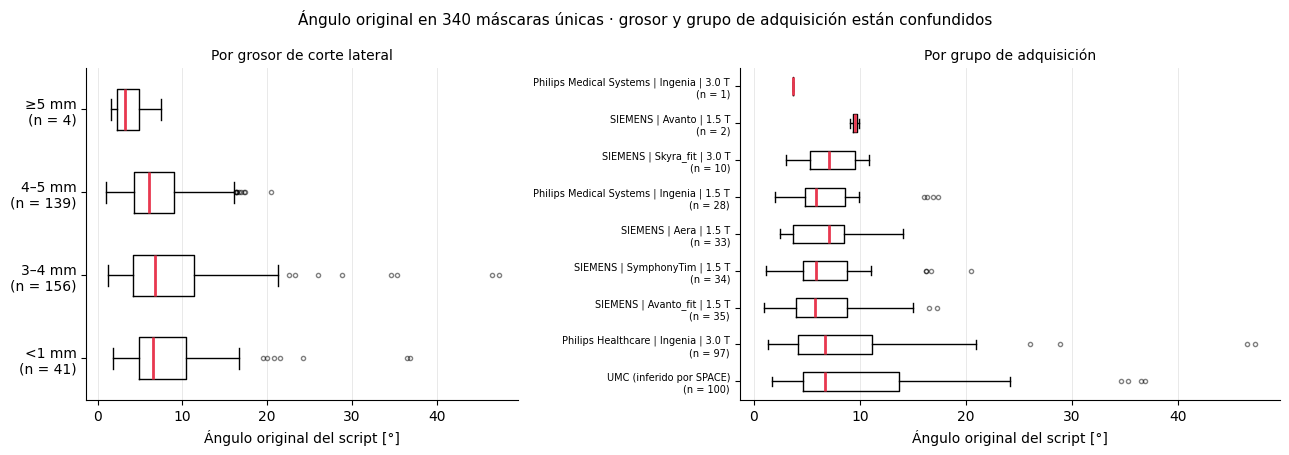

In [26]:
# 6. Ángulo original por grosor de corte y por grupo de adquisición (máscaras únicas)
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib, matplotlib.pyplot as plt

def resumen_angulo(df, por):
    r = (df.groupby(por)["angulo_original"]
           .agg(n="count", mediana="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75),
                minimo="min", maximo="max").round(2))
    r["pct_par_con_201"] = (100 * df.groupby(por)["par_original_incluye_201"].mean()).round(1)
    return r

por_grosor = resumen_angulo(unicas, "grosor_lr_rango").reindex([g for g in ORDEN_GROSOR if g in set(unicas["grosor_lr_rango"])])
por_grupo = resumen_angulo(unicas, "grupo_adquisicion").sort_values("n", ascending=False)
avanto = unicas[unicas["escaner"].str.contains("Avanto_fit")]
por_avanto = resumen_angulo(avanto, ["grupo_adquisicion", "grosor_lr_rango"])
por_grosor.to_csv(DIR_SALIDA / "angulo_por_grosor.csv")
por_grupo.to_csv(DIR_SALIDA / "angulo_por_grupo_adquisicion.csv")
por_avanto.to_csv(DIR_SALIDA / "angulo_avanto_fit_por_grosor.csv")
print("Ángulo original por rango de grosor lateral [°]\n" + por_grosor.to_string())
print("\nÁngulo original por grupo de adquisición [°]\n" + por_grupo.to_string())
print("\nSolo Siemens Avanto_fit, por grupo de adquisición y grosor [°]\n" + por_avanto.to_string())

def caja(ax, grupos, etiquetas, titulo):
    ax.boxplot(grupos, vert=False, widths=0.5, tick_labels=etiquetas,
               medianprops={"color": "#e8384f", "lw": 2}, flierprops={"ms": 3, "alpha": 0.5})
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("Ángulo original del script [°]")
    ax.grid(axis="x", color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
caja(axes[0], [unicas.loc[unicas["grosor_lr_rango"] == g, "angulo_original"] for g in por_grosor.index],
     [f"{g}\n(n = {n})" for g, n in por_grosor["n"].items()], "Por grosor de corte lateral")
caja(axes[1], [unicas.loc[unicas["grupo_adquisicion"] == e, "angulo_original"] for e in por_grupo.index],
     [f"{e}\n(n = {n})" for e, n in por_grupo["n"].items()], "Por grupo de adquisición")
axes[1].tick_params(axis="y", labelsize=7)
fig.suptitle(f"Ángulo original en {len(unicas)} máscaras únicas · grosor y grupo de adquisición están confundidos", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_angulo_por_grosor_y_grupo.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer las tablas y las gráficas:** cada caja resume el ángulo original de un grupo de máscaras únicas; la línea roja es la mediana. La columna `pct_par_con_201` indica en qué porcentaje de las máscaras del grupo el par elegido incluye la cara inferior del disco 201, el hallazgo principal del cuaderno 03.

**Qué muestra:** las medianas son muy parecidas entre grosores: 6,59° con menos de 1 mm, 6,80° con 3–4 mm y 6,08° con 4–5 mm; el grupo de 5 mm o más tiene solo 4 máscaras y no permite comparar. Donde sí hay diferencias es en la cola alta: los grupos de menos de 1 mm y de 3–4 mm, que reúnen al centro universitario y al Philips Ingenia de 3 T, concentran los ángulos mayores de 20°, mientras que el grupo de 4–5 mm no pasa de 20,4°. El contraste dentro del Avanto_fit apunta en la misma dirección: el centro universitario, con cortes de 3–4 mm, y los demás estudios con ese escáner, con cortes de 4–5 mm, tienen la misma mediana (6,70° y 6,68°), pero el primero llega mucho más alto (p75 de 13,89° frente a 9,15°). Por lo tanto, la descripción no muestra un corrimiento sistemático del ángulo con el grosor; las diferencias aparecen en los extremos, y pueden deberse tanto a quién se estudió en cada centro como al grosor, sin que estos datos permitan separar ambas cosas. La proporción de máscaras cuyo par incluye el disco 201 varía entre el 29 % y el 57 % en los grupos de adquisición con al menos 10 máscaras, sin una relación clara con el grosor.

## Parte 2 · Misma columna: serie fina frente a series estándar

En los estudios que tienen T2 SPACE, el mismo paciente tiene además series T1 y T2 estándar, con cortes de 3 a 5 mm y segmentadas por separado. La celda 7 compara, dentro de cada estudio, el ángulo de la T2 SPACE con el de cada serie estándar. La diferencia mezcla el grosor de corte con la secuencia y con la segmentación manual, así que no se atribuye solo al grosor, pero sí acota cuánto puede variar el ángulo de una misma columna entre series.

Estudios con T2 SPACE: 41 · comparaciones con máscaras estándar distintas: 59
Diferencia estándar − SPACE [°]: mediana -0.29, p25 -0.86, p75 -0.04, mínimo -3.33, máximo 6.84
Diferencia absoluta [°]: mediana 0.56, p75 1.01 · mayor de 2°: 8 · mayor de 5°: 1
Mismo par de discos que la T2 SPACE: 40 de 59


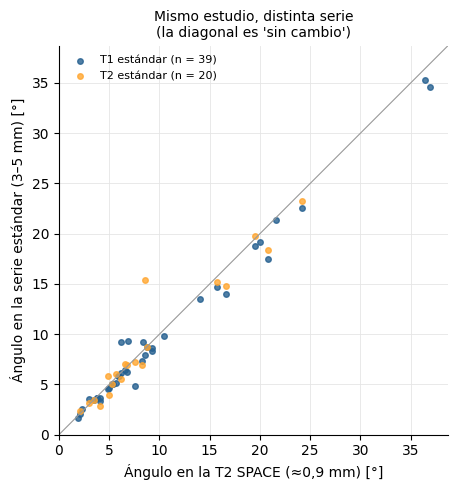

In [27]:
# 7. Dentro del mismo estudio: T2 SPACE frente a T1 y T2 estándar
space = series[series["secuencia"] == "t2_SPACE"].set_index("estudio")
filas = []
for _, s in series[series["secuencia"].isin(["t1", "t2"]) & series["estudio"].isin(space.index)].iterrows():
    f = space.loc[s["estudio"]]
    filas.append({"estudio": s["estudio"], "serie_estandar": s["serie"], "secuencia_estandar": s["secuencia"],
                  "espaciado_estandar_mm": s["espaciado_lr_mm"], "angulo_space": f["angulo_original"],
                  "angulo_estandar": s["angulo_original"], "dif_estandar_menos_space": s["angulo_original"] - f["angulo_original"],
                  "mismo_par": (s["disco_inf_original"] == f["disco_inf_original"]) and (s["disco_sup_original"] == f["disco_sup_original"]),
                  "misma_mascara_t1_t2": False})
pares = pd.DataFrame(filas)
# Si la T1 y la T2 estándar de un estudio comparten máscara, solo se cuenta una de las dos
md5 = series.set_index("serie")["mascara_md5"]
pares["mascara_md5"] = pares["serie_estandar"].map(md5)
pares["misma_mascara_t1_t2"] = pares.duplicated(["estudio", "mascara_md5"], keep=False)
pares_u = pares.drop_duplicates(["estudio", "mascara_md5"], keep="first")
pares.to_csv(DIR_SALIDA / "space_frente_a_estandar.csv", index=False)

d = pares_u["dif_estandar_menos_space"]
print(f"Estudios con T2 SPACE: {len(space)} · comparaciones con máscaras estándar distintas: {len(pares_u)}")
print(f"Diferencia estándar − SPACE [°]: mediana {d.median():.2f}, p25 {d.quantile(.25):.2f}, p75 {d.quantile(.75):.2f}, "
      f"mínimo {d.min():.2f}, máximo {d.max():.2f}")
print(f"Diferencia absoluta [°]: mediana {d.abs().median():.2f}, p75 {d.abs().quantile(.75):.2f} · "
      f"mayor de 2°: {(d.abs() > 2).sum()} · mayor de 5°: {(d.abs() > 5).sum()}")
print(f"Mismo par de discos que la T2 SPACE: {pares_u['mismo_par'].sum()} de {len(pares_u)}")

fig, ax = plt.subplots(figsize=(5.4, 5))
limite = np.nanmax(pares_u[["angulo_space", "angulo_estandar"]].to_numpy()) * 1.05
ax.plot([0, limite], [0, limite], color="#999999", lw=0.8)
for sec, color in (("t1", "#245f8f"), ("t2", "#ffa630")):
    p = pares_u[pares_u["secuencia_estandar"] == sec]
    ax.scatter(p["angulo_space"], p["angulo_estandar"], s=16, color=color, alpha=0.8, label=f"{sec.upper()} estándar (n = {len(p)})")
ax.set_xlim(0, limite); ax.set_ylim(0, limite); ax.set_aspect("equal")
ax.set_xlabel("Ángulo en la T2 SPACE (≈0,9 mm) [°]"); ax.set_ylabel("Ángulo en la serie estándar (3–5 mm) [°]")
ax.set_title("Mismo estudio, distinta serie\n(la diagonal es 'sin cambio')", fontsize=10)
ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True); ax.legend(fontsize=8, frameon=False)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_space_frente_a_estandar.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer la gráfica:** cada punto es un estudio con T2 SPACE comparado con una de sus series estándar; si la T1 y la T2 estándar del estudio comparten la misma máscara, se cuenta una sola vez. Los puntos sobre la diagonal tienen el mismo ángulo en las dos series.

**Qué muestra:** en los 41 estudios con T2 SPACE hay 59 comparaciones con máscaras estándar distintas. La serie estándar tiende a dar un ángulo apenas menor que la T2 SPACE del mismo paciente: la mediana de la diferencia es −0,29°, con rango intercuartílico de −0,86° a −0,04°. En valor absoluto, la mediana es de 0,56°, y la diferencia supera 2° en 8 comparaciones y 5° en una sola (6,84°, en la serie 35_t2). El par de discos elegido coincide en 40 de las 59. Por lo tanto, entre dos series de la misma columna el ángulo suele cambiar menos de un grado, pero el par cambia en un tercio de los casos, lo que indica que la selección del par es más frágil que el valor del ángulo. Los dos puntos de la esquina superior derecha son los estudios 162 y 18, en los que la serie estándar da entre 1,1° y 2,3° menos que la T2 SPACE. Como aquí cambian a la vez el grosor, la secuencia y la segmentación, la parte 3 sirve para ver cuánto de esta diferencia, y de su tendencia a la baja, se debe solo al grosor.

## Parte 3 · Experimento de engrosamiento

### Qué se simula

Una serie sagital estándar no ve la columna cada 0,9 mm en sentido lateral, sino cada 3,3 o 4,4 mm. Para saber cuánto afecta eso al ángulo, cada máscara T2 SPACE se convierte en una máscara de cortes gruesos a lo largo del eje lateral, se le pasa al script tal como está y se compara su ángulo con el de la máscara fina original. Los otros dos ejes no se tocan.

El eje lateral se identifica por la dirección de cada eje de la imagen: es aquel cuyo vector de dirección tiene la mayor componente derecha–izquierda. La celda 8a comprueba además que su espaciado coincide con el `espaciado_lr_mm` del inventario.

### Dos métodos

Si el corte grueso $k$ cubre el intervalo lateral $[c_k - T/2,\ c_k + T/2]$, de grosor $T$ y centro $c_k$:

- **Vecino más cercano:** el corte grueso copia el corte fino cuyo centro está más cerca de $c_k$. Simula tomar una muestra delgada cada $T$ milímetros, sin volumen parcial.
- **Etiqueta mayoritaria:** cada vóxel del corte grueso toma la etiqueta que ocupa más espesor dentro del intervalo, ponderando cada corte fino por la longitud que comparte con él. Simula el efecto de volumen parcial de un corte grueso real, que promedia todo lo que hay en su espesor.

Ninguno de los dos reproduce exactamente una adquisición real seguida de una segmentación manual; por eso se usan ambos y se compara cuánto difieren.

### Tres posiciones del primer corte

Dónde empieza el primer corte grueso es arbitrario, y la misma columna puede quedar cortada por sitios distintos. Por eso cada combinación de grosor y método se repite con el primer corte desplazado 0, 1/3 y 2/3 del grosor. La variación del ángulo entre esas tres posiciones mide cuánto depende el resultado de dónde caen los cortes, y no solo de su grosor.

### Diseño completo

Para cada una de las 41 máscaras T2 SPACE se corre el script en la máscara original (la base) y en 2 grosores × 2 métodos × 3 desplazamientos = 12 máscaras engrosadas: 533 corridas en total. De cada corrida se guardan los planos de todas las caras, como en el cuaderno 03, de modo que el ángulo original y las variantes A, B y AB se calculan después sin volver a correr nada.

In [28]:
# 8a. Función de engrosamiento y comprobación de identidad
import SimpleITK as sitk

def eje_lateral(img):
    "Índice (orden SimpleITK x, y, z) del eje de la imagen que apunta en dirección derecha–izquierda."
    D = np.array(img.GetDirection()).reshape(3, 3)
    return int(np.argmax(np.abs(D[0, :])))           # columna j: dirección del eje j; fila 0: componente x (LPS)

def engrosar(img, grosor, desfase, metodo):
    "Simula cortes laterales de `grosor` mm; `desfase` es la fracción del grosor que se corre el primer corte."
    j = eje_lateral(img)
    eje_np = 2 - j                                    # GetArrayFromImage invierte el orden de los ejes
    a = np.moveaxis(sitk.GetArrayFromImage(img), eje_np, 0)
    s0, n0 = img.GetSpacing()[j], a.shape[0]
    inicio, fin = -s0 / 2, (n0 - 0.5) * s0           # extensión física del volumen fino sobre el eje lateral
    centros = inicio + desfase * grosor + (np.arange(int(np.ceil((fin - inicio) / grosor)) + 1) + 0.5) * grosor
    centros = centros[centros <= fin]
    centros_finos = np.arange(n0) * s0
    salida = np.zeros((len(centros),) + a.shape[1:], dtype=a.dtype)
    for k, c in enumerate(centros):
        if metodo == "vecino":
            salida[k] = a[int(np.clip(np.rint(c / s0), 0, n0 - 1))]
        elif metodo == "mayoritaria":
            solape = (np.minimum(centros_finos + s0 / 2, c + grosor / 2)
                      - np.maximum(centros_finos - s0 / 2, c - grosor / 2)).clip(min=0)
            idx = np.nonzero(solape > 1e-9)[0]
            bloque, w = a[idx], solape[idx]
            etiquetas = np.unique(bloque)
            puntaje = np.stack([(w[:, None, None] * (bloque == e)).sum(0) for e in etiquetas])
            salida[k] = etiquetas[np.argmax(puntaje, axis=0)]
        else:
            raise ValueError(f"Método desconocido: {metodo}")
    nueva = sitk.GetImageFromArray(np.moveaxis(salida, 0, eje_np))
    espaciado = list(img.GetSpacing()); espaciado[j] = grosor
    D = np.array(img.GetDirection()).reshape(3, 3)
    nueva.SetSpacing(espaciado)
    nueva.SetDirection(img.GetDirection())
    nueva.SetOrigin(tuple(np.array(img.GetOrigin()) + D[:, j] * centros[0]))
    return nueva

# El eje lateral de cada máscara coincide con el espaciado lateral del inventario
esp_inv = series.set_index("serie")["espaciado_lr_mm"]
for ruta in mascaras:
    img = sitk.ReadImage(str(ruta))
    s = img.GetSpacing()[eje_lateral(img)]
    assert abs(s - esp_inv[ruta.stem]) < 0.01, f"{ruta.stem}: eje lateral de {s:.3f} mm y el inventario dice {esp_inv[ruta.stem]:.3f} mm"
print(f"Eje lateral identificado en las {len(mascaras)} máscaras, con el espaciado del inventario")

# Con el grosor igual al fino y sin desplazamiento, los dos métodos deben devolver la máscara original exacta
img = sitk.ReadImage(str(mascaras[0]))
for metodo in METODOS:
    copia = engrosar(img, img.GetSpacing()[eje_lateral(img)], 0, metodo)
    identica = (np.array_equal(sitk.GetArrayFromImage(copia), sitk.GetArrayFromImage(img))
                and np.allclose(copia.GetOrigin(), img.GetOrigin()) and np.allclose(copia.GetSpacing(), img.GetSpacing()))
    print(f"Identidad con '{metodo}' en {mascaras[0].stem}: {identica}")
    assert identica, "El engrosamiento no reproduce la máscara original con el grosor fino"

Eje lateral identificado en las 41 máscaras, con el espaciado del inventario
Identidad con 'vecino' en 107_t2_SPACE: True
Identidad con 'mayoritaria' en 107_t2_SPACE: True


In [29]:
# 8b. Funciones para correr el script y guardar los planos (las mismas del cuaderno 03)
import csv, time, tempfile, traceback, io, contextlib, shutil
matplotlib.use("Agg")                   # el script llama plt.show(); así no se intenta abrir una ventana por corrida

VARIANTES = {   # nombre: (ángulo por cara que se usa, discos excluidos)
    "original":  ("angulo_coronal_script", ()),
    "A_sin_201": ("angulo_coronal_script", (DISCO_CAUDAL,)),
    "B_arcsen":  ("arcsen_nx", ()),
    "AB":        ("arcsen_nx", (DISCO_CAUDAL,)),
}

def ejecutar_script(ruta):
    "Corre el script adaptado sobre una máscara y devuelve su espacio de nombres."
    with tempfile.TemporaryDirectory() as ti, tempfile.TemporaryDirectory() as to:
        shutil.copy(ruta, Path(ti) / ruta.name)
        fuente = (codigo.replace("mask_path = Path('path/to/spine/segmentations')", f"mask_path = Path({ti!r})")
                        .replace("image_path = Path('path/to/output/images')", f"image_path = Path({to!r})"))
        ns = {"__name__": "compute_cobb_angle"}
        mostrar_original, figuras_previas = plt.show, set(plt.get_fignums())
        plt.show = lambda *a, **k: None
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(fuente, "compute-Cobb-angle_numpy2.py", "exec"), ns)
        finally:
            plt.show = mostrar_original
            for num in set(plt.get_fignums()) - figuras_previas:
                plt.close(num)
    return ns

def filas_de_planos(ns, **ident):
    "Una fila por cara de disco con los planos que ajustó el script, más las columnas de identificación."
    labels, discos = [int(l) for l in ns["labels"]], ns["all_discs"]
    d_inf, d_sup = labels[ns["index_highest_vertebra"]], labels[ns["index_lowest_vertebra"]]   # nombres del script
    filas = []
    for lab in labels:
        d = discos[lab]
        for cara, normal, punto, angulo, seleccion, elegida in (
                ("inferior", d.normal_L, d.point_L, d.angle_L, d.lower, lab == d_inf),
                ("superior", d.normal_U, d.point_U, d.angle_U, d.upper, lab == d_sup)):
            n = np.asarray(normal, dtype=float)
            u = n / np.linalg.norm(n)
            filas.append({**ident, "disco": lab, "cara": cara,
                          "nx": n[0], "ny": n[1], "nz": n[2], "px": punto[0], "py": punto[1], "pz": punto[2],
                          "n_vertices": int(np.sum(seleccion)),
                          "angulo_coronal_script": float(angulo),
                          "arcsen_nx": float(np.degrees(np.arcsin(np.clip(u[0], -1, 1)))),
                          "inclinacion_sagital": float(np.degrees(np.arctan(u[1] / u[2]))),
                          "elegida_script": bool(elegida), "angulo_script": float(ns["angle"])})
    return filas

def maximo_como_el_script(caras, columna, excluir=()):
    "Misma matriz y mismo argmax que compute-Cobb-angle.py, con la columna y las exclusiones indicadas."
    inf = caras[caras["cara"] == "inferior"].set_index("disco")[columna]
    sup = caras[caras["cara"] == "superior"].set_index("disco")[columna]
    labels = sorted(int(l) for l in inf.index if int(l) not in excluir)
    if len(labels) < 2:
        return np.nan, np.nan, np.nan
    overview = np.zeros([len(labels), len(labels)])
    for i, l_inf in enumerate(labels):
        for j, l_sup in enumerate(labels):
            if l_inf < l_sup:
                overview[i, j] = sup[l_sup] - inf[l_inf]
    overview = np.absolute(overview)
    i, j = np.unravel_index(overview.argmax(), overview.shape)
    return float(overview.max()), labels[i], labels[j]

def variantes_de(caras):
    fila = {}
    for nombre, (columna, excluir) in VARIANTES.items():
        angulo, d_inf, d_sup = maximo_como_el_script(caras, columna, excluir)
        fila[f"angulo_{nombre}"], fila[f"disco_inf_{nombre}"], fila[f"disco_sup_{nombre}"] = angulo, d_inf, d_sup
    return fila

CONDICIONES = [("base", "base", np.nan, np.nan)] + [
    (f"{m}_{g}mm_d{round(o * 3)}", m, g, o) for g in GROSORES_MM for m in METODOS for o in DESFASES]
print(f"{len(CONDICIONES)} condiciones por máscara:", ", ".join(c[0] for c in CONDICIONES))

13 condiciones por máscara: base, vecino_3.3mm_d0, vecino_3.3mm_d1, vecino_3.3mm_d2, mayoritaria_3.3mm_d0, mayoritaria_3.3mm_d1, mayoritaria_3.3mm_d2, vecino_4.4mm_d0, vecino_4.4mm_d1, vecino_4.4mm_d2, mayoritaria_4.4mm_d0, mayoritaria_4.4mm_d1, mayoritaria_4.4mm_d2


## Ejecución

La celda 9 recorre las 41 máscaras y, para cada una, las 13 condiciones. Cada máscara engrosada se escribe en una carpeta temporal de Colab, se le pasa al script y se borra; no se guarda en Drive porque puede regenerarse en segundos con la misma función. De cada corrida se agregan las caras a `planos_engrosamiento.csv` y después la corrida a `registro_corrida.csv`; si Colab se corta entre las dos escrituras, la corrida se repite y la celda 10 descarta las filas duplicadas.

In [30]:
# 9. Correr el script en la base y en cada máscara engrosada (retoma donde iba si se interrumpe)
CSV_PLANOS = DIR_SALIDA / "planos_engrosamiento.csv"
CSV_REGISTRO = DIR_SALIDA / "registro_corrida.csv"
COLUMNAS_REGISTRO = ["serie", "condicion", "angulo_script", "n_discos", "n_cortes_laterales", "estado", "segundos", "detalle"]

hechas = set()
if CSV_REGISTRO.exists():
    r = pd.read_csv(CSV_REGISTRO, dtype={"serie": str})
    hechas = set(zip(r["serie"], r["condicion"]))
else:
    with open(CSV_REGISTRO, "w", newline="") as f:
        csv.writer(f).writerow(COLUMNAS_REGISTRO)
pendientes = [(ruta, c) for ruta in mascaras for c in CONDICIONES if (ruta.stem, c[0]) not in hechas]
print(f"Corridas hechas: {len(hechas)} | pendientes: {len(pendientes)} (≈ {len(pendientes) * 20 / 3600:.1f} h)")

for i, (ruta, (condicion, metodo, grosor, desfase)) in enumerate(pendientes, 1):
    t0 = time.time()
    angulo, n_discos, n_cortes, estado, detalle = np.nan, 0, 0, "error", ""
    try:
        img = sitk.ReadImage(str(ruta))
        if condicion == "base":
            entrada = ruta
            n_cortes = img.GetSize()[eje_lateral(img)]
        else:
            gruesa = engrosar(img, grosor, desfase, metodo)
            n_cortes = gruesa.GetSize()[eje_lateral(gruesa)]
            entrada = DIR_GRUESAS / f"{ruta.stem}__{condicion}.mha"
            sitk.WriteImage(gruesa, str(entrada), True)
        ns = ejecutar_script(entrada)
        angulo = float(ns["all_scans"][entrada.stem])
        if condicion != "base":
            entrada.unlink()
        if angulo == 9999:
            estado = "sin_discos (el script asigna 9999)"
        else:
            caras = pd.DataFrame(filas_de_planos(ns, serie=ruta.stem, condicion=condicion, metodo=metodo,
                                                 grosor_mm=grosor, desfase=desfase))
            caras.to_csv(CSV_PLANOS, mode="a", header=not CSV_PLANOS.exists(), index=False)
            n_discos, estado = int(caras["disco"].nunique()), "ok"
    except Exception as e:
        detalle = f"{type(e).__name__}: {e}"
        traceback.print_exc()
    finally:
        plt.close("all")
    with open(CSV_REGISTRO, "a", newline="") as f:
        csv.writer(f).writerow([ruta.stem, condicion, angulo, n_discos, n_cortes, estado, round(time.time() - t0, 1), detalle])
    if i % 13 == 0 or i == len(pendientes):
        print(f"{i}/{len(pendientes)} · última: {ruta.stem} {condicion} = {angulo:.2f}° ({estado})")

Corridas hechas: 533 | pendientes: 0 (≈ 0.0 h)


## Tabla por serie y condición, con controles

La celda 10 hace cuatro comprobaciones antes de describir los resultados:

1. Todas las corridas terminaron con estado `ok`.
2. En cada corrida, el ángulo original recalculado desde los planos guardados reproduce exactamente el ángulo y el par que devolvió el script.
3. La condición base reproduce el ángulo y el par que el cuaderno 03 obtuvo para cada T2 SPACE. Si no, algo cambió en el entorno entre corridas.
4. Se cuenta en cuántas corridas engrosadas cambió el número de discos respecto a la base. Un disco perdido o partido cambia los candidatos del script, así que esas corridas se señalan aparte.

`angulos_engrosamiento.csv` tiene una fila por serie y condición, con el ángulo y el par de cada variante y la diferencia respecto a la base.

In [31]:
# 10. Tabla por serie y condición, con los controles de consistencia
planos = (pd.read_csv(CSV_PLANOS, dtype={"serie": str})
            .drop_duplicates(["serie", "condicion", "disco", "cara"], keep="last"))
registro = (pd.read_csv(CSV_REGISTRO, dtype={"serie": str})
              .drop_duplicates(["serie", "condicion"], keep="last"))
print("Corridas por estado:\n" + registro["estado"].value_counts().to_string())

# Control 1: todas las corridas terminaron bien
assert len(registro) == len(mascaras) * len(CONDICIONES) and (registro["estado"] == "ok").all(), \
    "Hay corridas pendientes o con error: revisar registro_corrida.csv antes de seguir"

filas = []
for (serie, condicion), caras in planos.groupby(["serie", "condicion"], sort=False):
    elegidas = caras[caras["elegida_script"]]
    filas.append({"serie": serie, "condicion": condicion, "metodo": caras["metodo"].iloc[0],
                  "grosor_mm": caras["grosor_mm"].iloc[0], "desfase": caras["desfase"].iloc[0],
                  "n_discos": caras["disco"].nunique(), "angulo_script": caras["angulo_script"].iloc[0],
                  "disco_inf_script": int(elegidas.loc[elegidas["cara"] == "inferior", "disco"].iloc[0]),
                  "disco_sup_script": int(elegidas.loc[elegidas["cara"] == "superior", "disco"].iloc[0]),
                  **variantes_de(caras)})
eng = pd.DataFrame(filas)

# Control 2: el original recalculado desde los planos es exactamente lo que devolvió el script
dif_original = (eng["angulo_original"] - eng["angulo_script"]).abs().max()
mismo_par = ((eng["disco_inf_original"] == eng["disco_inf_script"]) & (eng["disco_sup_original"] == eng["disco_sup_script"])).all()
print(f"\nControl 2 · |original − script|, máximo en {len(eng)} corridas: {dif_original:.2e}° · mismo par en todas: {mismo_par}")
assert dif_original < 1e-9 and mismo_par

# Control 3: la base reproduce el cuaderno 03
base = eng[eng["condicion"] == "base"].set_index("serie")
ref = series.set_index("serie").loc[base.index]
dif_03 = (base["angulo_original"] - ref["angulo_original"]).abs().max()
par_03 = ((base["disco_inf_original"] == ref["disco_inf_original"]) & (base["disco_sup_original"] == ref["disco_sup_original"])).all()
print(f"Control 3 · |base − cuaderno 03|, máximo en {len(base)} series: {dif_03:.2e}° · mismo par en todas: {par_03}")
assert dif_03 < 1e-6 and par_03, "La base no reproduce el cuaderno 03: revisar el entorno antes de seguir"

# Diferencias respecto a la base de la misma serie
for nombre in VARIANTES:
    eng[f"base_{nombre}"] = eng["serie"].map(base[f"angulo_{nombre}"])
    eng[f"dif_{nombre}"] = eng[f"angulo_{nombre}"] - eng[f"base_{nombre}"]
eng["cambia_par_original"] = ((eng["disco_inf_original"] != eng["serie"].map(base["disco_inf_original"]))
                              | (eng["disco_sup_original"] != eng["serie"].map(base["disco_sup_original"])))
eng["n_discos_base"] = eng["serie"].map(base["n_discos"])
eng["cambia_n_discos"] = eng["n_discos"] != eng["n_discos_base"]
eng["par_base_incluye_201"] = eng["serie"].map(base["disco_inf_original"] == DISCO_CAUDAL)

# Control 4: corridas engrosadas con un número de discos distinto al de la base
gruesas = eng[eng["condicion"] != "base"]
print(f"Control 4 · corridas engrosadas con distinto número de discos que la base: "
      f"{gruesas['cambia_n_discos'].sum()} de {len(gruesas)}")
if gruesas["cambia_n_discos"].any():
    print(gruesas.loc[gruesas["cambia_n_discos"], ["serie", "condicion", "n_discos_base", "n_discos"]].to_string(index=False))

orden = (["serie", "condicion", "metodo", "grosor_mm", "desfase", "n_discos", "n_discos_base", "cambia_n_discos",
          "par_base_incluye_201", "cambia_par_original"]
         + [f"{p}_{n}" for n in VARIANTES for p in ("angulo", "base", "dif", "disco_inf", "disco_sup")])
eng = eng[orden].sort_values(["serie", "condicion"]).reset_index(drop=True)
eng.to_csv(DIR_SALIDA / "angulos_engrosamiento.csv", index=False)
print(f"\nGuardado angulos_engrosamiento.csv: {len(eng)} filas ({len(base)} series × {len(CONDICIONES)} condiciones)")

Corridas por estado:
estado
ok    533

Control 2 · |original − script|, máximo en 533 corridas: 7.11e-15° · mismo par en todas: True
Control 3 · |base − cuaderno 03|, máximo en 41 series: 1.78e-15° · mismo par en todas: True
Control 4 · corridas engrosadas con distinto número de discos que la base: 0 de 492

Guardado angulos_engrosamiento.csv: 533 filas (41 series × 13 condiciones)


## Descripción del resultado

Todo lo que sigue es descriptivo; no hay prueba de hipótesis porque no se definió una pregunta para ella, y no hay exactitud porque no hay estándar de referencia. La celda 11a resume cuánto cambia el ángulo original con cada grosor y método. La 11b mide cuánto depende de la posición del primer corte. La 11c compara los dos métodos entre sí, y la 11d revisa si las variantes del cuaderno 03 son más o menos sensibles al grosor que el original. La 11e dibuja los casos con mayor cambio, y la 11f revisa la dirección del cambio, si es proporcional al ángulo y por qué cambia el par de discos. Las celdas 11g a 11j agregan intervalos de confianza, el acuerdo entre series del mismo estudio, la parte de ese acuerdo que explica el grosor y el mecanismo por cara. Cada celda va seguida de una lectura de lo que muestra.

Diferencia engrosada − base del ángulo original [°] (negativo: el engrosamiento reduce el ángulo)
                       corridas  mediana   p25   p75  mediana_abs  p90_abs  maximo_abs  cambia_par  cambia_n_discos
grosor_mm metodo                                                                                                   
3.3       mayoritaria       123    -0.22 -0.53 -0.06         0.25     0.84        2.24          19                0
          vecino            123    -0.23 -0.53 -0.07         0.26     0.75        2.31          17                0
4.4       mayoritaria       123    -0.42 -0.66 -0.11         0.45     1.22        2.94          24                0
          vecino            123    -0.39 -0.60 -0.11         0.42     1.05        2.56          26                0


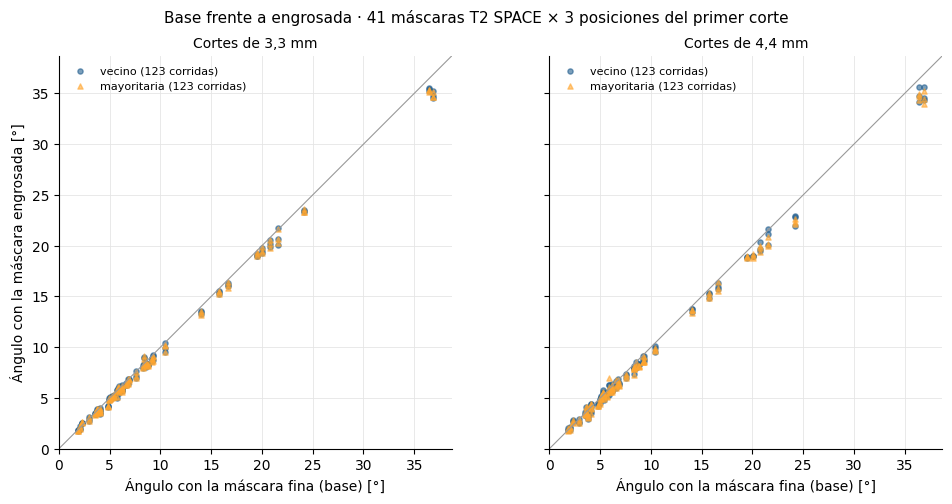

In [32]:
# 11a. Cuánto cambia el ángulo original con el grosor y el método
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")   # la celda 9 dejó matplotlib en modo sin pantalla (Agg)
gruesas = eng[eng["condicion"] != "base"]
resumen_grosor = (gruesas.groupby(["grosor_mm", "metodo"])
                  .agg(corridas=("dif_original", "size"),
                       mediana=("dif_original", "median"),
                       p25=("dif_original", lambda s: s.quantile(.25)),
                       p75=("dif_original", lambda s: s.quantile(.75)),
                       mediana_abs=("dif_original", lambda s: s.abs().median()),
                       p90_abs=("dif_original", lambda s: s.abs().quantile(.9)),
                       maximo_abs=("dif_original", lambda s: s.abs().max()),
                       cambia_par=("cambia_par_original", "sum"),
                       cambia_n_discos=("cambia_n_discos", "sum"))
                  .round(2))
resumen_grosor.to_csv(DIR_SALIDA / "resumen_por_grosor.csv")
print("Diferencia engrosada − base del ángulo original [°] (negativo: el engrosamiento reduce el ángulo)")
print(resumen_grosor.to_string())

fig, axes = plt.subplots(1, len(GROSORES_MM), figsize=(5.2 * len(GROSORES_MM), 5), sharex=True, sharey=True)
limite = np.nanmax(eng[["angulo_original", "base_original"]].to_numpy()) * 1.05
for ax, g in zip(np.atleast_1d(axes), GROSORES_MM):
    ax.plot([0, limite], [0, limite], color="#999999", lw=0.8)
    for metodo, color, marca in (("vecino", "#245f8f", "o"), ("mayoritaria", "#ffa630", "^")):
        p = gruesas[(gruesas["grosor_mm"] == g) & (gruesas["metodo"] == metodo)]
        ax.scatter(p["base_original"], p["angulo_original"], s=14, color=color, marker=marca, alpha=0.6,
                   label=f"{metodo} ({len(p)} corridas)")
    ax.set_xlim(0, limite); ax.set_ylim(0, limite); ax.set_aspect("equal")
    ax.set_title(f"Cortes de {str(g).replace('.', ',')} mm", fontsize=10)
    ax.set_xlabel("Ángulo con la máscara fina (base) [°]")
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True); ax.legend(fontsize=8, frameon=False)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
np.atleast_1d(axes)[0].set_ylabel("Ángulo con la máscara engrosada [°]")
fig.suptitle(f"Base frente a engrosada · {len(base)} máscaras T2 SPACE × 3 posiciones del primer corte", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_base_frente_a_engrosada.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer la tabla y las gráficas:** cada fila de la tabla reúne las corridas de un grosor y un método (41 máscaras × 3 posiciones del primer corte). Las columnas `mediana`, `p25` y `p75` describen la diferencia con signo, y `mediana_abs`, `p90_abs` y `maximo_abs`, su tamaño sin importar la dirección. En las gráficas, cada punto es una corrida, y los puntos sobre la diagonal dan el mismo ángulo que la máscara fina.

**Qué muestra:** al engrosar la máscara, el ángulo casi siempre baja, y lo hace poco. Con cortes de 3,3 mm, la mediana de la diferencia es −0,22° con la etiqueta mayoritaria y −0,23° con el vecino más cercano, y el rango intercuartílico va de −0,53° a −0,06°. Con 4,4 mm, la mediana baja a −0,42° y −0,39°, y el rango intercuartílico va de −0,66° a −0,11°. Como los dos rangos quedan enteros por debajo de cero, la reducción es sistemática y no un ruido que se compensa, y además crece con el grosor. En tamaño absoluto, la mediana es de 0,25° con 3,3 mm y de 0,42°–0,45° con 4,4 mm; nueve de cada diez corridas cambian menos de 0,84° y 1,22°, respectivamente, y el mayor cambio observado es de 2,94°, por debajo de los 5° que van der Graaf *et al.* consideran un error de medición clínicamente aceptable. En las gráficas, los puntos se apartan de la diagonal a medida que crece el ángulo de la base, lo que sugiere que la reducción es aproximadamente proporcional al ángulo y no un número fijo de grados. El par de discos cambia en 36 de 246 corridas con 3,3 mm y en 50 de 246 con 4,4 mm, y ninguna corrida perdió ni ganó un disco, así que los cambios de ángulo no se deben a máscaras rotas por el engrosamiento.

Rango del ángulo original entre las tres posiciones del primer corte, por máscara [°]
                       count  mean   std   min   25%   50%   75%   90%   max
grosor_mm metodo                                                            
3.3       mayoritaria   41.0  0.36  0.25  0.07  0.19  0.32  0.47  0.65  1.40
          vecino        41.0  0.38  0.30  0.03  0.21  0.31  0.48  0.72  1.67
4.4       mayoritaria   41.0  0.46  0.27  0.08  0.27  0.42  0.57  0.78  1.29
          vecino        41.0  0.50  0.36  0.05  0.25  0.46  0.58  0.97  1.57


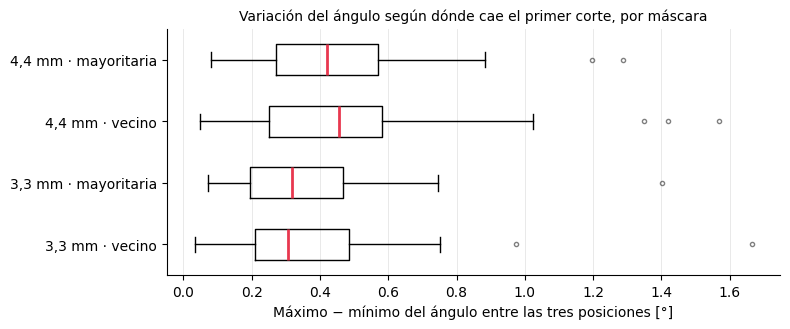

In [33]:
# 11b. Cuánto depende el ángulo de dónde cae el primer corte
rango = (gruesas.groupby(["serie", "grosor_mm", "metodo"])["angulo_original"]
                .agg(lambda s: s.max() - s.min()).rename("rango_entre_desfases").reset_index())
resumen_desfase = (rango.groupby(["grosor_mm", "metodo"])["rango_entre_desfases"]
                        .describe(percentiles=[.25, .5, .75, .9]).round(2))
resumen_desfase.to_csv(DIR_SALIDA / "resumen_por_desfase.csv")
print("Rango del ángulo original entre las tres posiciones del primer corte, por máscara [°]")
print(resumen_desfase.to_string())

grupos_d = [(g, m) for g in GROSORES_MM for m in METODOS]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot([rango.loc[(rango["grosor_mm"] == g) & (rango["metodo"] == m), "rango_entre_desfases"] for g, m in grupos_d],
           vert=False, widths=0.5, tick_labels=[f"{str(g).replace('.', ',')} mm · {m}" for g, m in grupos_d],
           medianprops={"color": "#e8384f", "lw": 2}, flierprops={"ms": 3, "alpha": 0.5})
ax.set_xlabel("Máximo − mínimo del ángulo entre las tres posiciones [°]")
ax.set_title("Variación del ángulo según dónde cae el primer corte, por máscara", fontsize=10)
ax.grid(axis="x", color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_variacion_por_desfase.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer la tabla y la gráfica:** para cada máscara, grosor y método se toma la diferencia entre el mayor y el menor de los tres ángulos obtenidos al desplazar el primer corte. Un rango de 0 significa que la posición de los cortes no importa; un rango alto, que el ángulo depende de dónde caen.

**Qué muestra:** cambiar solo dónde cae el primer corte mueve el ángulo de una misma máscara una mediana de 0,31°–0,32° con cortes de 3,3 mm y de 0,42°–0,46° con 4,4 mm; en nueve de cada diez máscaras el rango queda por debajo de 0,65°–0,97°, y el máximo es de 1,67°. Estas cifras son del mismo orden que la reducción mediana de la celda 11a (0,22°–0,42°). Esto significa que, en una serie real, en la que no se sabe dónde cayeron los cortes respecto a la columna, la posición de los cortes aporta una variación tan grande como el efecto sistemático del grosor. Por lo tanto, la reducción de la celda 11a se puede describir en conjunto, pero no se puede corregir serie por serie con un factor fijo. Tanto la variación como la reducción aumentan al pasar de 3,3 a 4,4 mm, lo que es coherente con que ambas provengan del mismo muestreo lateral más espaciado.

In [34]:
# 11c. Vecino más cercano frente a etiqueta mayoritaria (mismo grosor y misma posición del primer corte)
pivote = gruesas.pivot_table(index=["serie", "grosor_mm", "desfase"], columns="metodo", values="angulo_original")
pivote["mayoritaria_menos_vecino"] = pivote["mayoritaria"] - pivote["vecino"]
resumen_metodo = (pivote.groupby("grosor_mm")["mayoritaria_menos_vecino"]
                        .agg(n="size", mediana="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75),
                             mediana_abs=lambda s: s.abs().median(), maximo_abs=lambda s: s.abs().max()).round(2))
resumen_metodo.to_csv(DIR_SALIDA / "resumen_por_metodo.csv")
print("Diferencia mayoritaria − vecino en el ángulo original [°]")
print(resumen_metodo.to_string())

Diferencia mayoritaria − vecino en el ángulo original [°]
             n  mediana   p25   p75  mediana_abs  maximo_abs
grosor_mm                                                   
3.3        123    -0.01 -0.03  0.02         0.03        0.43
4.4        123    -0.03 -0.12  0.03         0.06        0.96


**Cómo leer la tabla:** cada fila compara, para un grosor, el ángulo que dan los dos métodos en la misma máscara y con la misma posición del primer corte. Si los dos métodos simulan el grosor de forma parecida, las diferencias deberían ser pequeñas frente a las de la celda 11a.

**Qué muestra:** los dos métodos de engrosamiento dan prácticamente el mismo ángulo. La mediana de la diferencia entre ambos es −0,01° con 3,3 mm y −0,03° con 4,4 mm, y en valor absoluto, 0,03° y 0,06°; la mayor diferencia es de 0,43° y 0,96°. Son diferencias de un orden de magnitud menor que las de la celda 11a. Por lo tanto, el resultado del experimento no depende de cómo se simule el volumen parcial, y lo que pesa es el espaciado entre cortes. Esto es una inferencia sobre los dos métodos simulados, no sobre una adquisición real, en la que el volumen parcial ocurre en la imagen y después lo interpreta quien segmenta.

In [35]:
# 11d. ¿Las variantes del cuaderno 03 son más o menos sensibles al grosor que el original?
filas = []
for (g, m), df in gruesas.groupby(["grosor_mm", "metodo"]):
    fila = {"grosor_mm": g, "metodo": m}
    for nombre in VARIANTES:
        fila[f"mediana_abs_{nombre}"] = df[f"dif_{nombre}"].abs().median()
        fila[f"p90_abs_{nombre}"] = df[f"dif_{nombre}"].abs().quantile(.9)
    filas.append(fila)
sensibilidad = pd.DataFrame(filas).set_index(["grosor_mm", "metodo"]).round(2)
sensibilidad.to_csv(DIR_SALIDA / "sensibilidad_por_variante.csv")
print("Cambio absoluto respecto a la base, por variante [°]")
print(sensibilidad.to_string())

por_201 = (gruesas.groupby(["grosor_mm", "par_base_incluye_201"])["dif_original"]
                  .agg(corridas="size", mediana_abs=lambda s: s.abs().median(), p90_abs=lambda s: s.abs().quantile(.9)).round(2))
print("\nCambio absoluto del original según si el par de la base incluye el disco 201 [°]")
print(por_201.to_string())

Cambio absoluto respecto a la base, por variante [°]
                       mediana_abs_original  p90_abs_original  mediana_abs_A_sin_201  p90_abs_A_sin_201  mediana_abs_B_arcsen  p90_abs_B_arcsen  mediana_abs_AB  p90_abs_AB
grosor_mm metodo                                                                                                                                                           
3.3       mayoritaria                  0.25              0.84                   0.23               0.80                  0.25              0.82            0.23        0.79
          vecino                       0.26              0.75                   0.23               0.79                  0.25              0.78            0.23        0.74
4.4       mayoritaria                  0.45              1.22                   0.34               1.05                  0.38              1.02            0.33        1.02
          vecino                       0.42              1.05                   0.33   

**Cómo leer las tablas:** la primera compara, para cada grosor y método, cuánto cambia cada una de las cuatro columnas del cuaderno 03 al engrosar la máscara. La segunda separa las corridas según si el par elegido en la máscara fina incluía la cara inferior del disco 201.

**Qué muestran:** con cortes de 3,3 mm, las cuatro columnas cambian casi lo mismo (mediana absoluta de 0,23° a 0,26°). Con 4,4 mm, el original es el que más cambia (0,42°–0,45°), seguido de B (0,36°–0,38°), y A y AB son las que menos (0,33°–0,34°); en el percentil 90 el orden es el mismo. Las diferencias entre columnas son de una décima de grado, así que ninguna de las variantes del cuaderno 03 vuelve el ángulo claramente más o menos robusto al grosor.

La segunda tabla separa las 16 máscaras cuyo par en la máscara fina incluye la cara inferior del disco 201 (96 corridas) de las 25 restantes (150 corridas). La mediana del cambio es parecida en los dos grupos (0,27° frente a 0,25° con 3,3 mm y 0,45° frente a 0,39° con 4,4 mm), y el percentil 90 es incluso menor cuando el par incluye el 201 (0,70° frente a 0,85° y 0,87° frente a 1,26°). Por lo tanto, el engrosamiento no desestabiliza de forma especial los ángulos que decide el disco 201. Lo que el cuaderno 03 describió sobre ese disco ya está presente en la máscara fina, y el grosor de corte no lo crea ni lo corrige.

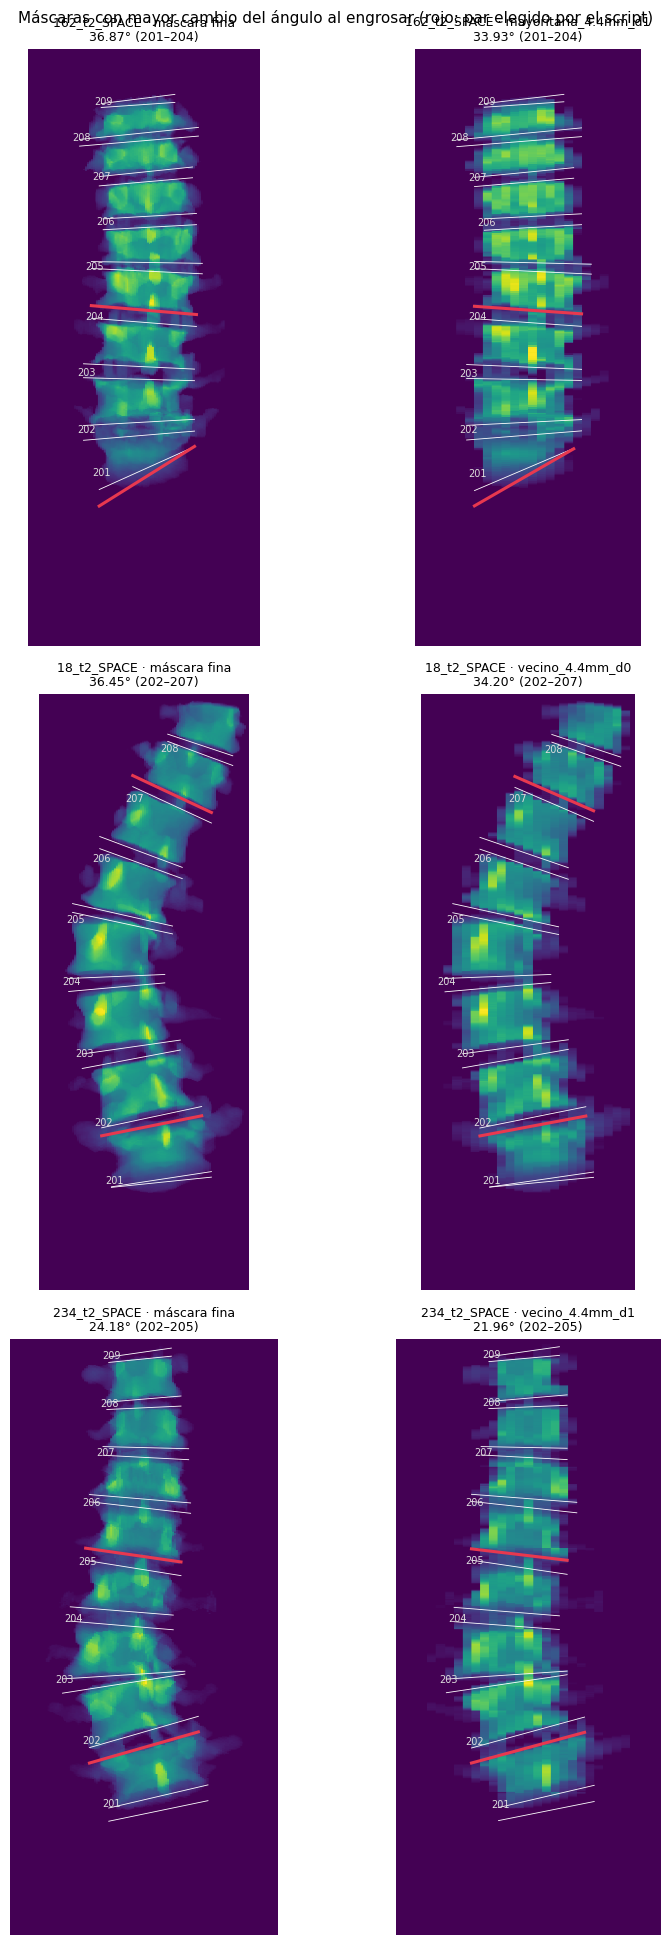

       serie            condicion  base_original  angulo_original  dif_original  disco_inf_original  disco_sup_original  cambia_par_original  cambia_n_discos
162_t2_SPACE mayoritaria_4.4mm_d1          36.87            33.93         -2.94                 201                 204                False            False
 18_t2_SPACE      vecino_4.4mm_d0          36.45            34.20         -2.25                 202                 207                False            False
234_t2_SPACE      vecino_4.4mm_d1          24.18            21.96         -2.22                 202                 205                False            False


In [36]:
# 11e. Casos con mayor cambio: máscara fina frente a la engrosada que más se aleja
N_EXTREMOS = 3   # @param {type:"integer"}

def dibujar_par(ax, ns, titulo, color="#e8384f"):
    "Proyección coronal del script con todas las caras (blanco) y el par elegido por el script."
    discos, a_tangente = ns["all_discs"], ns["plane_to_tangent"]
    labels = [int(l) for l in ns["labels"]]
    d_inf, d_sup = labels[ns["index_highest_vertebra"]], labels[ns["index_lowest_vertebra"]]
    ax.imshow(ns["image2D"].T)
    for lab, d in discos.items():
        for punto, normal in ((d.point_L, d.normal_L), (d.point_U, d.normal_U)):
            x, z = a_tangente(d.verts, punto, normal)
            ax.plot(x, z, color="white", lw=0.6)
        ax.text(d.verts[:, 0].max() + 6, d.verts[:, 2].mean(), str(lab), fontsize=7, va="center", color="#dddddd")
    for lab, punto, normal in ((d_inf, discos[d_inf].point_L, discos[d_inf].normal_L),
                               (d_sup, discos[d_sup].point_U, discos[d_sup].normal_U)):
        x, z = a_tangente(discos[lab].verts, punto, normal)
        ax.plot(x, z, color=color, lw=2.2)
    ax.invert_yaxis(); ax.invert_xaxis(); ax.axis("off")
    ax.set_title(f"{titulo}\n{ns['angle']:.2f}° ({d_inf}–{d_sup})", fontsize=9)

idx = gruesas["dif_original"].abs().groupby(gruesas["serie"]).idxmax()        # la peor corrida de cada máscara
peores = gruesas.loc[idx].assign(abs_dif=lambda d: d["dif_original"].abs()).nlargest(N_EXTREMOS, "abs_dif")
peores.to_csv(DIR_EXTREMOS / "casos_extremos.csv", index=False)
condiciones = {c[0]: c for c in CONDICIONES}

fig, axes = plt.subplots(len(peores), 2, figsize=(9, 6.6 * len(peores)), squeeze=False)
for (ax_base, ax_gruesa), (_, p) in zip(axes, peores.iterrows()):
    ruta = DIR_LOCAL / f"{p['serie']}.mha"
    dibujar_par(ax_base, ejecutar_script(ruta), f"{p['serie']} · máscara fina")
    _, metodo, grosor, desfase = condiciones[p["condicion"]]
    entrada = DIR_GRUESAS / f"{p['serie']}__{p['condicion']}.mha"
    sitk.WriteImage(engrosar(sitk.ReadImage(str(ruta)), grosor, desfase, metodo), str(entrada), True)
    dibujar_par(ax_gruesa, ejecutar_script(entrada), f"{p['serie']} · {p['condicion']}")
    entrada.unlink()
fig.suptitle("Máscaras con mayor cambio del ángulo al engrosar (rojo: par elegido por el script)", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_EXTREMOS / "panel_casos_extremos.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()
print(peores[["serie", "condicion", "base_original", "angulo_original", "dif_original", "disco_inf_original",
              "disco_sup_original", "cambia_par_original", "cambia_n_discos"]].round(2).to_string(index=False))

**Cómo leer el panel:** cada fila es una máscara. A la izquierda está la proyección coronal que usa el script con la máscara fina, y a la derecha la misma columna con la condición de engrosamiento que más alejó su ángulo de la base; en rojo, el par que elige el script. La celda toma las `N_EXTREMOS` máscaras cuya peor corrida tuvo el mayor cambio, así que al cambiar ese valor cambian los casos mostrados.

**Con el valor por defecto (`N_EXTREMOS = 3`):** las tres máscaras con mayor cambio son 162_t2_SPACE (de 36,87° a 33,93°), 18_t2_SPACE (de 36,45° a 34,20°) y 234_t2_SPACE (de 24,18° a 21,96°). Las tres alcanzan su mayor cambio con cortes de 4,4 mm, y son también las tres de mayor ángulo en la máscara fina, lo que es coherente con una reducción que crece con el ángulo. En las tres se mantiene el par de discos y el número de discos. En la imagen, la máscara engrosada muestra el borde lateral escalonado de los cortes gruesos, pero los planos que ajusta el script quedan en la misma posición y con una inclinación apenas menor. En 162_t2_SPACE el ángulo sigue definido por la cara inferior del disco 201 (par 201–204), así que el engrosamiento reduce el valor en unos 3° sin cambiar el problema descrito en el cuaderno 03.

Dirección del cambio del ángulo original al engrosar
           corridas  corridas_que_bajan  corridas_que_suben  mascaras_con_mediana_negativa  mascaras
grosor_mm                                                                                           
3.3             246                 205                  41                             37        41
4.4             246                 201                  45                             36        41

Cambio relativo (engrosada − base) / base [%]
           mediana  p25  p75
grosor_mm                   
3.3           -3.3 -5.5 -1.1
4.4           -4.8 -7.2 -2.1
Spearman entre el ángulo base y la mediana del cambio con 3,3 mm: -0.70
Spearman entre el ángulo base y la mediana del cambio con 4,4 mm: -0.80

Mediana del cambio por tramo del ángulo base [°]
            mascaras  mediana_cambio_3,3mm  mediana_cambio_4,4mm
tramo_base                                                      
0–5°              12                 -0.10              

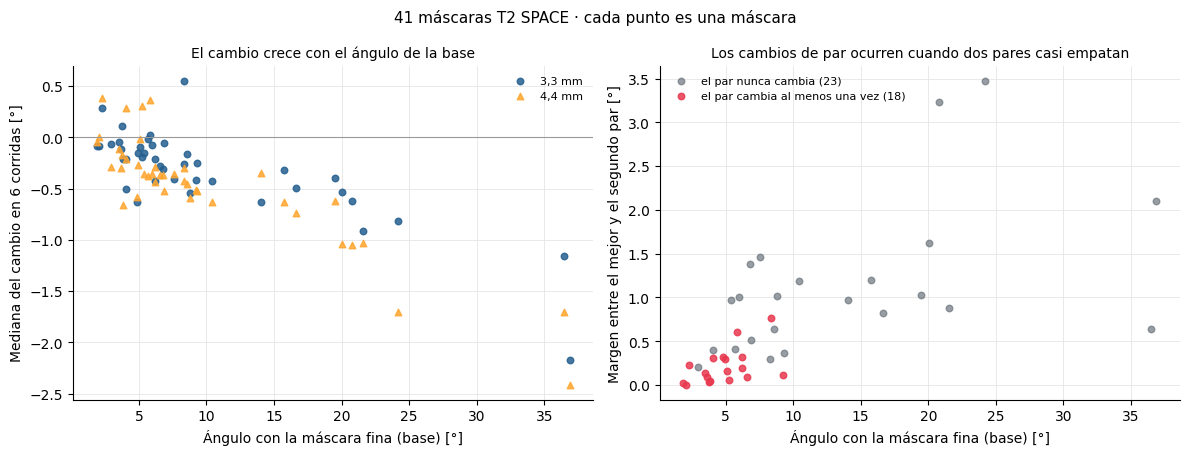

In [37]:
# 11f. Dirección, proporcionalidad y cambios de par (sin volver a correr el script)
from scipy.stats import spearmanr

# 1) Dirección: ¿cuántas corridas y cuántas máscaras bajan el ángulo?
direccion = (gruesas.groupby("grosor_mm")
             .agg(corridas=("dif_original", "size"),
                  corridas_que_bajan=("dif_original", lambda s: int((s < 0).sum())),
                  corridas_que_suben=("dif_original", lambda s: int((s > 0).sum()))))
por_mascara = gruesas.groupby(["grosor_mm", "serie"])["dif_original"].median()
direccion["mascaras_con_mediana_negativa"] = por_mascara.lt(0).groupby("grosor_mm").sum().astype(int)
direccion["mascaras"] = por_mascara.groupby("grosor_mm").size()
print("Dirección del cambio del ángulo original al engrosar\n" + direccion.to_string())

# 2) Proporcionalidad: cambio relativo y relación con el ángulo de la base
relativo_por_corrida = gruesas.assign(cambio_relativo_pct=100 * gruesas["dif_original"] / gruesas["base_original"])
relativo = (relativo_por_corrida.groupby("grosor_mm")["cambio_relativo_pct"]
            .agg(mediana="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75)).round(1))
print("\nCambio relativo (engrosada − base) / base [%]\n" + relativo.to_string())

med = por_mascara.unstack("grosor_mm")                       # mediana de las 6 corridas de cada máscara y grosor
med["base_original"] = base["angulo_original"]
for g in GROSORES_MM:
    rho = spearmanr(med["base_original"], med[g]).statistic
    print(f"Spearman entre el ángulo base y la mediana del cambio con {str(g).replace('.', ',')} mm: {rho:.2f}")
TRAMOS = [0, 5, 10, 20, 90]
med["tramo_base"] = pd.cut(med["base_original"], TRAMOS, right=False,
                           labels=[f"{a}–{b}°" if b < 90 else f"≥{a}°" for a, b in zip(TRAMOS[:-1], TRAMOS[1:])])
por_tramo = med.groupby("tramo_base", observed=True).agg(
    mascaras=("base_original", "size"),
    **{f"mediana_cambio_{str(g).replace('.', ',')}mm": (g, "median") for g in GROSORES_MM}).round(2)
print("\nMediana del cambio por tramo del ángulo base [°]\n" + por_tramo.to_string())

# 3) Cambios de par: ¿en qué máscaras ocurren y por qué?
def margen_entre_pares(caras):
    "Diferencia entre el mayor y el segundo mayor |sup − inf| de la matriz del script (mismos pares candidatos)."
    inf = caras[caras["cara"] == "inferior"].set_index("disco")["angulo_coronal_script"]
    sup = caras[caras["cara"] == "superior"].set_index("disco")["angulo_coronal_script"]
    valores = sorted((abs(sup[b] - inf[a]) for a in inf.index for b in sup.index if a < b), reverse=True)
    return valores[0] - valores[1]

margen = (planos[planos["condicion"] == "base"].groupby("serie").apply(margen_entre_pares, include_groups=False)
          .rename("margen_base"))
pares = gruesas.groupby("serie").agg(corridas_con_cambio_de_par=("cambia_par_original", "sum"))
pares = pares.join(margen).join(base["angulo_original"].rename("base_original"))
pares["alguna_vez_cambia"] = pares["corridas_con_cambio_de_par"] > 0
print(f"\nMáscaras con al menos un cambio de par: {pares['alguna_vez_cambia'].sum()} de {len(pares)}")
print(pares.groupby("alguna_vez_cambia")[["base_original", "margen_base"]]
           .describe(percentiles=[.5]).round(2).to_string())
efecto_par = gruesas.groupby("cambia_par_original")["dif_original"].agg(
    corridas="size", mediana_abs=lambda s: s.abs().median(), maximo_abs=lambda s: s.abs().max()).round(2)
print("\nCambio absoluto del ángulo según si cambió el par [°]\n" + efecto_par.to_string())
rho_m = spearmanr(pares["margen_base"], pares["corridas_con_cambio_de_par"]).statistic
print(f"Spearman entre el margen de la base y el número de corridas con cambio de par: {rho_m:.2f}")

direccion.join(relativo.add_prefix("cambio_relativo_pct_")).to_csv(DIR_SALIDA / "direccion_y_cambio_relativo.csv")
por_tramo.to_csv(DIR_SALIDA / "cambio_por_tramo_de_angulo.csv")
pares.to_csv(DIR_SALIDA / "cambios_de_par_y_margen.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for g, color, marca in ((3.3, "#245f8f", "o"), (4.4, "#ffa630", "^")):
    axes[0].scatter(med["base_original"], med[g], s=22, color=color, marker=marca, alpha=0.85,
                    label=f"{str(g).replace('.', ',')} mm")
axes[0].axhline(0, color="#999999", lw=0.8)
axes[0].set_xlabel("Ángulo con la máscara fina (base) [°]")
axes[0].set_ylabel("Mediana del cambio en 6 corridas [°]")
axes[0].set_title("El cambio crece con el ángulo de la base", fontsize=10)
axes[0].legend(fontsize=8, frameon=False)
cambia = pares["alguna_vez_cambia"]
axes[1].scatter(pares.loc[~cambia, "base_original"], pares.loc[~cambia, "margen_base"], s=22, color="#6c757d",
                alpha=0.7, label=f"el par nunca cambia ({(~cambia).sum()})")
axes[1].scatter(pares.loc[cambia, "base_original"], pares.loc[cambia, "margen_base"], s=22, color="#e8384f",
                alpha=0.85, label=f"el par cambia al menos una vez ({cambia.sum()})")
axes[1].set_xlabel("Ángulo con la máscara fina (base) [°]")
axes[1].set_ylabel("Margen entre el mejor y el segundo par [°]")
axes[1].set_title("Los cambios de par ocurren cuando dos pares casi empatan", fontsize=10)
axes[1].legend(fontsize=8, frameon=False)
for ax in axes:
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
fig.suptitle(f"{len(base)} máscaras T2 SPACE · cada punto es una máscara", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_proporcionalidad_y_pares.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer las tablas y las gráficas:** la primera tabla cuenta cuántas corridas bajan o suben el ángulo y en cuántas máscaras la mediana de sus seis corridas es negativa. La segunda expresa el cambio como porcentaje del ángulo de la base, y la tercera agrupa las máscaras por su ángulo en la máscara fina. Para los cambios de par se calcula, en la máscara fina, el *margen* entre el par que elige el script y el segundo mejor par de la misma matriz: un margen pequeño significa que dos pares casi empatan. En la gráfica de la izquierda cada punto es una máscara y su mediana de cambio para un grosor; en la de la derecha, cada punto es una máscara, en rojo si su par cambió en al menos una de las 12 corridas engrosadas.

**Qué muestra:** el engrosamiento baja el ángulo en 205 de 246 corridas con 3,3 mm y en 201 de 246 con 4,4 mm, y la mediana por máscara es negativa en 37 y 36 de las 41 máscaras. La reducción relativa tiene una mediana de −3,3 % con 3,3 mm y de −4,8 % con 4,4 mm, y su tamaño en grados crece con el ángulo de la base (Spearman −0,70 y −0,80). Por tramos, la mediana del cambio con 4,4 mm va de −0,20° en las máscaras de menos de 5° a −1,38° en las de 20° o más. Por lo tanto, el efecto del grosor se describe mejor como una reducción proporcional de unos pocos puntos porcentuales que como un número fijo de grados. Esto es coherente con que los planos se aplanen un poco al muestrear el eje lateral con menos cortes, pero el cuaderno no mide ese mecanismo directamente, así que es una inferencia.

Los cambios de par se concentran en 18 de las 41 máscaras, todas con un ángulo base de 9,22° o menos. En ellas, el margen entre los dos mejores pares tiene una mediana de 0,15° y no pasa de 0,77°, mientras que en las 23 máscaras cuyo par nunca cambia la mediana es de 0,98°. Además, cuanto menor es el margen, más corridas cambian de par (Spearman −0,79). Cuando el par cambia, el ángulo se mueve menos que cuando no cambia (mediana absoluta de 0,22° frente a 0,40°, máximo de 1,05° frente a 2,94°), precisamente porque los dos pares daban casi el mismo valor. Esto significa que el cambio de par no es una falla del método, sino la consecuencia de un casi empate entre dos pares, propio de columnas con poca curvatura, y que su efecto sobre el ángulo es pequeño. El solapamiento entre los dos grupos de la gráfica (hay máscaras con margen de 0,2°–0,4° que nunca cambian) indica que el margen no basta para predecir el cambio en una máscara concreta.

### Precisión, acuerdo y mecanismo

Las cuatro celdas siguientes no vuelven a correr el script: trabajan con las tablas que ya existen. La 11g agrega intervalos de confianza a las medianas principales. La 11h mide el acuerdo entre la T2 SPACE y la serie estándar del mismo estudio con el método de Bland–Altman. La 11i separa, en esas mismas comparaciones, la parte que el grosor explica de la que no explica. La 11j revisa qué le pasa a cada cara de disco al engrosar, para comprobar con datos por qué el ángulo baja en proporción.

In [38]:
# 11g. Intervalos de confianza por bootstrap (se remuestrean máscaras o estudios completos, no corridas)
B_BOOTSTRAP = 2000      # repeticiones del bootstrap
SEMILLA = 20261018      # semilla fija: el cuaderno da los mismos intervalos cada vez que se ejecuta

def ic_bootstrap(df, unidad, estadistico, b=B_BOOTSTRAP, nivel=0.95, semilla=SEMILLA):
    """Valor e intervalo percentil remuestreando unidades completas: todas las filas de una unidad
    (por ejemplo, las seis corridas de una máscara) entran o salen juntas, porque no son independientes."""
    rng = np.random.default_rng(semilla)
    df = df.reset_index(drop=True)
    filas = [np.asarray(ix) for ix in df.groupby(unidad).indices.values()]
    valores = np.empty(b)
    for i in range(b):
        elegidas = rng.integers(0, len(filas), len(filas))
        valores[i] = estadistico(df.iloc[np.concatenate([filas[k] for k in elegidas])])
    a = (1 - nivel) / 2
    return estadistico(df), np.quantile(valores, a), np.quantile(valores, 1 - a)

filas_ic = []
def agregar(parte, medida, conjunto, df, unidad, estadistico):
    valor, inf, sup = ic_bootstrap(df, unidad, estadistico)
    filas_ic.append({"parte": parte, "medida": medida, "conjunto": conjunto, "unidades": df[unidad].nunique(),
                     "valor": valor, "ic95_inferior": inf, "ic95_superior": sup})

for g in GROSORES_MM:
    df = gruesas[gruesas["grosor_mm"] == g].assign(rel=lambda d: 100 * d["dif_original"] / d["base_original"])
    etiqueta = f"{str(g).replace('.', ',')} mm (6 corridas por máscara)"
    agregar("experimento", "mediana del cambio [°]", etiqueta, df, "serie", lambda d: d["dif_original"].median())
    agregar("experimento", "mediana del cambio absoluto [°]", etiqueta, df, "serie", lambda d: d["dif_original"].abs().median())
    agregar("experimento", "mediana del cambio relativo [%]", etiqueta, df, "serie", lambda d: d["rel"].median())
    agregar("experimento", "mediana del rango entre posiciones del primer corte [°]",
            f"{str(g).replace('.', ',')} mm (2 métodos por máscara)", rango[rango["grosor_mm"] == g], "serie",
            lambda d: d["rango_entre_desfases"].median())
agregar("misma columna", "mediana de la diferencia estándar − SPACE [°]", "59 comparaciones", pares_u, "estudio",
        lambda d: d["dif_estandar_menos_space"].median())
agregar("misma columna", "mediana de la diferencia absoluta [°]", "59 comparaciones", pares_u, "estudio",
        lambda d: d["dif_estandar_menos_space"].abs().median())

ic = pd.DataFrame(filas_ic)
ic[["valor", "ic95_inferior", "ic95_superior"]] = ic[["valor", "ic95_inferior", "ic95_superior"]].round(2)
ic.to_csv(DIR_SALIDA / "ic_bootstrap.csv", index=False)
print(f"Intervalos de confianza del 95 % por bootstrap percentil ({B_BOOTSTRAP} repeticiones, semilla {SEMILLA})")
print(ic.to_string(index=False))

Intervalos de confianza del 95 % por bootstrap percentil (2000 repeticiones, semilla 20261018)
        parte                                                  medida                        conjunto  unidades  valor  ic95_inferior  ic95_superior
  experimento                                  mediana del cambio [°] 3,3 mm (6 corridas por máscara)        41  -0.22          -0.34          -0.16
  experimento                         mediana del cambio absoluto [°] 3,3 mm (6 corridas por máscara)        41   0.26           0.19           0.35
  experimento                         mediana del cambio relativo [%] 3,3 mm (6 corridas por máscara)        41  -3.29          -3.94          -2.68
  experimento mediana del rango entre posiciones del primer corte [°]  3,3 mm (2 métodos por máscara)        41   0.31           0.24           0.37
  experimento                                  mediana del cambio [°] 4,4 mm (6 corridas por máscara)        41  -0.40          -0.48          -0.29
  experimen

**Cómo leer la tabla:** cada fila es una medida con su valor y su intervalo de confianza del 95 %, obtenido por bootstrap percentil con 2000 repeticiones y semilla fija. En el experimento se remuestrean máscaras, y en la comparación entre series se remuestrean estudios, porque las seis corridas de una misma máscara, o la T1 y la T2 de un mismo estudio, no son observaciones independientes. La columna `unidades` dice cuántas máscaras o estudios se remuestrearon.

**Qué muestra:** ninguno de los intervalos del experimento incluye el cero. La mediana del cambio es −0,22° con cortes de 3,3 mm (IC 95 %: −0,34° a −0,16°) y −0,40° con 4,4 mm (−0,48° a −0,29°), y en términos relativos, −3,29 % (−3,94 % a −2,68 %) y −4,82 % (−5,40 % a −3,81 %). El rango debido a la posición del primer corte, 0,31° (0,24° a 0,37°) y 0,43° (0,30° a 0,52°), se solapa con el cambio absoluto mediano, 0,26° (0,19° a 0,35°) y 0,42° (0,34° a 0,49°), lo que confirma que los dos efectos son del mismo tamaño. En la comparación entre series del mismo estudio, la mediana de la diferencia es −0,29° (−0,60° a −0,10°), y ese intervalo contiene la mediana del experimento con 3,3 mm. Estos intervalos describen la incertidumbre de muestreo dentro de 41 máscaras de un solo centro; no dicen nada sobre otros centros ni sobre otras poblaciones.

Comparaciones con distinta cantidad de discos que la T2 SPACE: 6 (35_t2, 55_t2, 57_t2, 98_t2, 118_t1, 118_t2)

Acuerdo estándar − SPACE [°], con IC del 95 % por bootstrap de estudios
                conjunto  comparaciones  estudios                                          medida  valor  ic95_inferior  ic95_superior
 todas las comparaciones             59        39                                           sesgo  -0.32          -0.70           0.05
 todas las comparaciones             59        39                                    lim_inferior  -3.09          -4.02          -1.92
 todas las comparaciones             59        39                                    lim_superior   2.44           1.13           3.76
 todas las comparaciones             59        39                            error_absoluto_medio   0.89           0.60           1.21
 todas las comparaciones             59        39 percentiles 2,5 y 97,5 (sin suponer normalidad)    NaN          -2.65           2.78
misma c

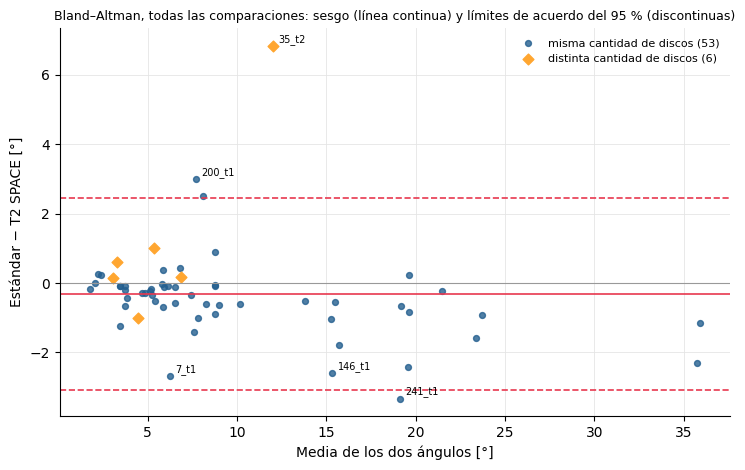

In [39]:
# 11h. Acuerdo entre la T2 SPACE y la serie estándar del mismo estudio (Bland–Altman)
n_discos = series.set_index("serie")["n_discos"]
ba = pares_u.assign(
    media=(pares_u["angulo_space"] + pares_u["angulo_estandar"]) / 2,
    n_discos_space=pares_u["estudio"].map(series[series["secuencia"] == "t2_SPACE"].set_index("estudio")["n_discos"]),
    n_discos_estandar=pares_u["serie_estandar"].map(n_discos))
ba["misma_cobertura"] = ba["n_discos_space"] == ba["n_discos_estandar"]

def acuerdo(d):
    "Sesgo, límites de acuerdo del 95 % (sesgo ± 1,96 DE) y error absoluto medio de la diferencia."
    x = d["dif_estandar_menos_space"]
    return {"sesgo": x.mean(), "lim_inferior": x.mean() - 1.96 * x.std(ddof=1),
            "lim_superior": x.mean() + 1.96 * x.std(ddof=1), "error_absoluto_medio": x.abs().mean()}

filas = []
for conjunto, df in (("todas las comparaciones", ba), ("misma cantidad de discos", ba[ba["misma_cobertura"]])):
    for medida in ("sesgo", "lim_inferior", "lim_superior", "error_absoluto_medio"):
        valor, inf, sup = ic_bootstrap(df, "estudio", lambda d, m=medida: acuerdo(d)[m])
        filas.append({"conjunto": conjunto, "comparaciones": len(df), "estudios": df["estudio"].nunique(),
                      "medida": medida, "valor": valor, "ic95_inferior": inf, "ic95_superior": sup})
    x = df["dif_estandar_menos_space"]
    filas.append({"conjunto": conjunto, "comparaciones": len(df), "estudios": df["estudio"].nunique(),
                  "medida": "percentiles 2,5 y 97,5 (sin suponer normalidad)",
                  "valor": np.nan, "ic95_inferior": x.quantile(.025), "ic95_superior": x.quantile(.975)})
tabla_ba = pd.DataFrame(filas).round(2)
tabla_ba.to_csv(DIR_SALIDA / "bland_altman_space_frente_a_estandar.csv", index=False)
ba.to_csv(DIR_SALIDA / "bland_altman_comparaciones.csv", index=False)
print(f"Comparaciones con distinta cantidad de discos que la T2 SPACE: {(~ba['misma_cobertura']).sum()} "
      f"({', '.join(ba.loc[~ba['misma_cobertura'], 'serie_estandar'])})")
print("\nAcuerdo estándar − SPACE [°], con IC del 95 % por bootstrap de estudios\n" + tabla_ba.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
a = acuerdo(ba)
for y, estilo in ((a["sesgo"], "-"), (a["lim_inferior"], "--"), (a["lim_superior"], "--")):
    ax.axhline(y, color="#e8384f", lw=1.2, ls=estilo)
ax.axhline(0, color="#999999", lw=0.8)
ax.scatter(ba.loc[ba["misma_cobertura"], "media"], ba.loc[ba["misma_cobertura"], "dif_estandar_menos_space"],
           s=18, color="#245f8f", alpha=0.8, label=f"misma cantidad de discos ({ba['misma_cobertura'].sum()})")
ax.scatter(ba.loc[~ba["misma_cobertura"], "media"], ba.loc[~ba["misma_cobertura"], "dif_estandar_menos_space"],
           s=30, color="#ffa630", marker="D", label=f"distinta cantidad de discos ({(~ba['misma_cobertura']).sum()})")
for _, f in ba[ba["dif_estandar_menos_space"].abs() > 2.5].iterrows():
    ax.annotate(f["serie_estandar"], (f["media"], f["dif_estandar_menos_space"]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("Media de los dos ángulos [°]"); ax.set_ylabel("Estándar − T2 SPACE [°]")
ax.set_title("Bland–Altman, todas las comparaciones: sesgo (línea continua) y límites de acuerdo del 95 % (discontinuas)", fontsize=9)
ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True); ax.legend(fontsize=8, frameon=False)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_bland_altman.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer la tabla y la gráfica:** en la gráfica de Bland–Altman cada punto es una comparación entre la T2 SPACE y una serie estándar del mismo estudio. El eje horizontal es la media de los dos ángulos y el vertical, su diferencia. La línea roja continua es el sesgo (la diferencia media) y las discontinuas son los límites de acuerdo del 95 %, sesgo ± 1,96 desviaciones estándar: el intervalo en el que se esperaría el 95 % de las diferencias si estas se distribuyeran de forma aproximadamente normal. Como hay algunos valores extremos, la tabla da también los percentiles 2,5 y 97,5 observados, que no dependen de ese supuesto. En naranja aparecen las comparaciones en las que la máscara estándar tiene una cantidad de discos distinta de la T2 SPACE, es decir, otra cobertura de la columna. Los intervalos de confianza se obtienen remuestreando estudios con la función de la celda 11g.

**Qué muestra:** con las 59 comparaciones (39 estudios), el sesgo es de −0,32° (IC 95 %: −0,70° a 0,05°), los límites de acuerdo van de −3,09° a 2,44° y el error absoluto medio es de 0,89°. Seis comparaciones tienen una cantidad de discos distinta, entre ellas 35_t2, la más extrema (+6,84°). Sin esas seis, el sesgo es de −0,51° (−0,84° a −0,19°), los límites se estrechan a −2,59° y 1,58°, y el error absoluto medio baja a 0,80°. Por lo tanto, en una misma columna, el ángulo de la serie estándar suele quedar a unos ±3° del de la T2 SPACE, con una ligera tendencia a ser menor. Los límites quedan dentro de los 5° que van der Graaf *et al.* consideran un error de medición aceptable, pero son imprecisos con 39 estudios: el intervalo del límite inferior llega a −4,02°. Este resultado complementa el ICC de 0,95 que reportan los autores entre las RM de baja y alta resolución, porque el ICC mide la consistencia frente a la variación entre pacientes, mientras que los límites de acuerdo dicen cuántos grados puede separarse una medida de la otra. Los dos ángulos salen del mismo algoritmo sobre máscaras manuales, así que esto es acuerdo entre series, no exactitud frente a un Cobb de referencia. Quedan diferencias grandes con la misma cantidad de discos, como 241_t1 (−3,33°), 200_t1 (+3,00°), 7_t1 (−2,69°) y 146_t1 (−2,60°), que la cobertura no explica; la celda 11i revisa si las explica el grosor.

Espaciado lateral de las series estándar [mm]: {'min': 3.241, '50%': 3.3, 'max': 3.333}

Diferencia observada (estándar − SPACE), predicha solo por el grosor y residuo [°]
conjunto                     todas las comparaciones  misma cantidad de discos
comparaciones                                  59.00                     53.00
mediana_observada                              -0.29                     -0.36
mediana_predicha_por_grosor                    -0.28                     -0.31
mediana_residuo                                -0.05                     -0.10
media_abs_observada                             0.89                      0.80
media_abs_residuo                               0.70                      0.57
varianza_observada                              1.99                      1.13
varianza_predicha                               0.14                      0.15
varianza_residuo                                1.72                      0.87
dentro_de_lo_simulado                 

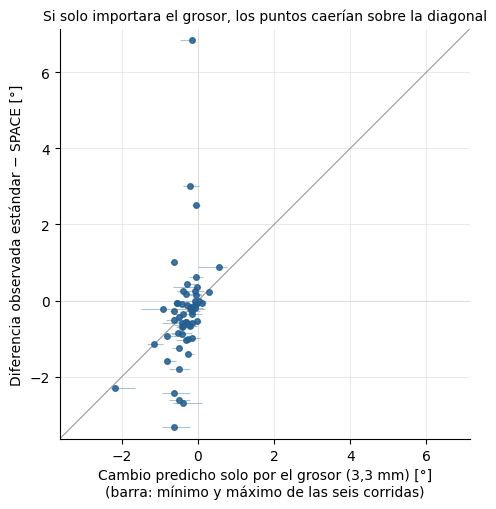

In [40]:
# 11i. ¿Cuánto de la diferencia entre series reales explica el grosor solo?
# Las series estándar de estos estudios tienen entre 3,24 y 3,33 mm de espaciado lateral, así que las seis
# corridas de 3,3 mm de cada máscara T2 SPACE sirven como predicción de lo que el grosor solo produciría.
print("Espaciado lateral de las series estándar [mm]:", pares_u["espaciado_estandar_mm"].describe()[["min", "50%", "max"]].round(3).to_dict())
sim = gruesas[gruesas["grosor_mm"] == 3.3].groupby("serie")["dif_original"].agg(prediccion="median", sim_min="min", sim_max="max")
desc = ba.assign(serie_space=ba["estudio"].astype(str) + "_t2_SPACE").join(sim, on="serie_space")   # estudio puede venir como número
desc["observada"] = desc["dif_estandar_menos_space"]
desc["residuo"] = desc["observada"] - desc["prediccion"]                 # lo que el grosor no explica
desc["dentro_de_lo_simulado"] = desc["observada"].between(desc["sim_min"], desc["sim_max"])
desc.to_csv(DIR_SALIDA / "grosor_frente_a_segmentacion.csv", index=False)

filas = []
for conjunto, df in (("todas las comparaciones", desc), ("misma cantidad de discos", desc[desc["misma_cobertura"]])):
    filas.append({"conjunto": conjunto, "comparaciones": len(df),
                  "mediana_observada": df["observada"].median(), "mediana_predicha_por_grosor": df["prediccion"].median(),
                  "mediana_residuo": df["residuo"].median(),
                  "media_abs_observada": df["observada"].abs().mean(), "media_abs_residuo": df["residuo"].abs().mean(),
                  "varianza_observada": df["observada"].var(), "varianza_predicha": df["prediccion"].var(),
                  "varianza_residuo": df["residuo"].var(),
                  "dentro_de_lo_simulado": int(df["dentro_de_lo_simulado"].sum())})
tabla_desc = pd.DataFrame(filas).set_index("conjunto").round(2)
tabla_desc.to_csv(DIR_SALIDA / "resumen_grosor_frente_a_segmentacion.csv")
print("\nDiferencia observada (estándar − SPACE), predicha solo por el grosor y residuo [°]")
print(tabla_desc.T.to_string())
rho = spearmanr(desc["prediccion"], desc["observada"]).statistic
print(f"\nSpearman entre la diferencia predicha y la observada: {rho:.2f}")

fig, ax = plt.subplots(figsize=(5.6, 5.2))
lim = [min(desc["observada"].min(), desc["prediccion"].min()) - 0.3, max(desc["observada"].max(), desc["prediccion"].max()) + 0.3]
ax.plot(lim, lim, color="#999999", lw=0.8)
ax.axhline(0, color="#dddddd", lw=0.8); ax.axvline(0, color="#dddddd", lw=0.8)
ax.errorbar(desc["prediccion"], desc["observada"],
            xerr=[desc["prediccion"] - desc["sim_min"], desc["sim_max"] - desc["prediccion"]],
            fmt="o", ms=4, color="#245f8f", ecolor="#9cb8cf", elinewidth=0.8, alpha=0.85)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("Cambio predicho solo por el grosor (3,3 mm) [°]\n(barra: mínimo y máximo de las seis corridas)")
ax.set_ylabel("Diferencia observada estándar − SPACE [°]")
ax.set_title("Si solo importara el grosor, los puntos caerían sobre la diagonal", fontsize=10)
ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_grosor_frente_a_segmentacion.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer la tabla y la gráfica:** las series estándar de estos estudios tienen entre 3,24 y 3,33 mm de espaciado lateral, así que lo que el experimento produjo al engrosar la misma máscara T2 SPACE a 3,3 mm es una predicción de cuánto cambiaría el ángulo solo por el grosor. Para cada comparación, la predicción es la mediana de esas seis corridas (dos métodos y tres posiciones del primer corte), y la barra horizontal de la gráfica va de la menor a la mayor. El residuo es la diferencia observada menos la predicha: lo que el grosor no explica. Según el artículo de SPIDER, las máscaras de las series estándar del centro universitario se generaron con la red de segmentación y se corrigieron a mano serie por serie; solo en los 20 estudios del arranque, de los que 15 quedaron en el conjunto de prueba no publicado, se obtuvieron remuestreando la segmentación de la T2 SPACE (van der Graaf *et al.*, *Sci Data* 2024, doi:[10.1038/s41597-024-03090-w](https://doi.org/10.1038/s41597-024-03090-w)). Por eso el residuo reúne sobre todo la segmentación de cada serie, la diferencia de secuencia, el movimiento del paciente entre adquisiciones y la cobertura.

**Qué muestra:** en mediana, el grosor explica casi toda la diferencia sistemática: la diferencia observada es de −0,29°, la predicha de −0,28° y el residuo de −0,05° (−0,36°, −0,31° y −0,10° cuando la cantidad de discos coincide). En cambio, el grosor explica poco de la dispersión. La varianza de la diferencia observada es de 1,99, la de la predicha de 0,14 y la del residuo de 1,72 (1,13, 0,15 y 0,87 con la misma cantidad de discos), y solo 18 de las 59 diferencias observadas caen dentro del rango de las seis corridas simuladas. La correlación entre lo predicho y lo observado es moderada (Spearman 0,53): donde el engrosamiento predice una caída mayor, que es en los ángulos grandes, la serie estándar también tiende a dar menos. Por lo tanto, la ligera tendencia de la serie estándar a dar un ángulo menor es la que se espera solo por el grosor, mientras que la variación de caso a caso, y con ella el ancho de los límites de acuerdo de la celda 11h, proviene sobre todo de otras fuentes. Con estos datos no se puede separar cuánto aporta cada una de ellas.

Caras con |ángulo coronal fino| ≥ 2° (las que entran en la mediana del cociente): 1032 por grosor y método
Cambio de cada cara de disco al engrosar (ángulos en °; cocientes adimensionales)
                       caras  pendiente_por_origen  mediana_cociente_caras_inclinadas  mediana_abs_cambio_coronal  mediana_abs_cambio_sagital  mediana_cociente_cobb
grosor_mm metodo                                                                                                                                                    
3.3       mayoritaria   1908                 0.966                              0.966                       0.146                       0.073                  0.967
          vecino        1908                 0.968                              0.968                       0.145                       0.074                  0.967
4.4       mayoritaria   1908                 0.950                              0.952                       0.201                       0.100          

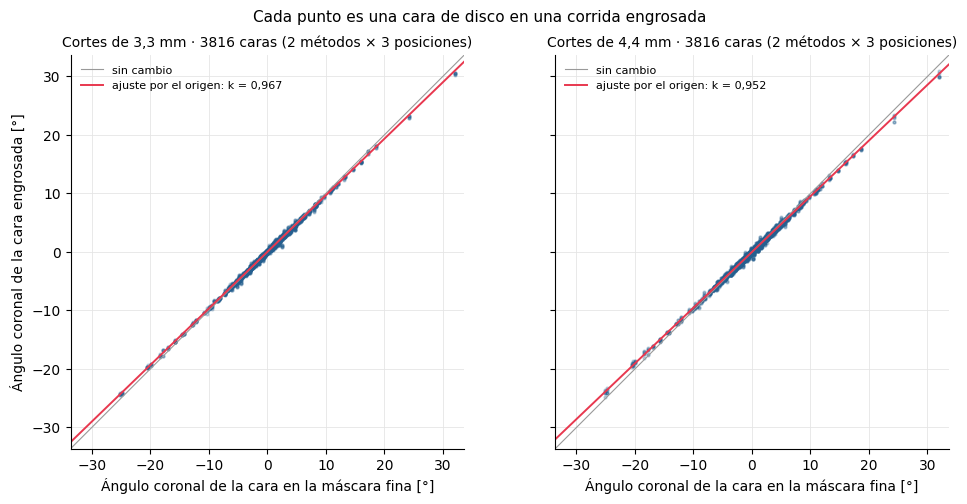

In [41]:
# 11j. Mecanismo: ¿cómo cambia cada cara de disco al engrosar?
cols = ["serie", "disco", "cara", "angulo_coronal_script", "inclinacion_sagital"]
caras_base = planos[planos["condicion"] == "base"][cols]
caras = (planos[planos["condicion"] != "base"][cols + ["metodo", "grosor_mm", "desfase"]]
         .merge(caras_base, on=["serie", "disco", "cara"], suffixes=("", "_base"), validate="many_to_one"))
caras["cambio_coronal"] = caras["angulo_coronal_script"] - caras["angulo_coronal_script_base"]
caras["cambio_sagital"] = caras["inclinacion_sagital"] - caras["inclinacion_sagital_base"]

def pendiente_por_origen(d):
    "Pendiente k de 'ángulo engrosado ≈ k · ángulo fino', ajustada sin intercepto."
    x, y = d["angulo_coronal_script_base"], d["angulo_coronal_script"]
    return (x * y).sum() / (x * x).sum()

inclinadas = caras["angulo_coronal_script_base"].abs() >= 2      # el cociente solo tiene sentido lejos de 0°
mecanismo = caras.groupby(["grosor_mm", "metodo"]).apply(lambda d: pd.Series({
    "caras": len(d),
    "pendiente_por_origen": pendiente_por_origen(d),
    "mediana_cociente_caras_inclinadas": (d["angulo_coronal_script"] / d["angulo_coronal_script_base"])[
        d["angulo_coronal_script_base"].abs() >= 2].median(),
    "mediana_abs_cambio_coronal": d["cambio_coronal"].abs().median(),
    "mediana_abs_cambio_sagital": d["cambio_sagital"].abs().median(),
}), include_groups=False)
mecanismo["caras"] = mecanismo["caras"].astype(int)
cobb = (gruesas.assign(cociente=gruesas["angulo_original"] / gruesas["base_original"])
               .groupby(["grosor_mm", "metodo"])["cociente"].median().rename("mediana_cociente_cobb"))
mecanismo = mecanismo.join(cobb).round(3)
mecanismo.to_csv(DIR_SALIDA / "mecanismo_por_cara.csv")
print(f"Caras con |ángulo coronal fino| ≥ 2° (las que entran en la mediana del cociente): {inclinadas.groupby([caras['grosor_mm'], caras['metodo']]).sum().iloc[0]} "
      "por grosor y método")
print("Cambio de cada cara de disco al engrosar (ángulos en °; cocientes adimensionales)\n" + mecanismo.to_string())

fig, axes = plt.subplots(1, len(GROSORES_MM), figsize=(5.2 * len(GROSORES_MM), 5), sharex=True, sharey=True)
lim = caras["angulo_coronal_script_base"].abs().max() * 1.05
for ax, g in zip(np.atleast_1d(axes), GROSORES_MM):
    d = caras[caras["grosor_mm"] == g]
    k = pendiente_por_origen(d)
    ax.plot([-lim, lim], [-lim, lim], color="#999999", lw=0.8, label="sin cambio")
    ax.scatter(d["angulo_coronal_script_base"], d["angulo_coronal_script"], s=4, color="#245f8f", alpha=0.25)
    ax.plot([-lim, lim], [-k * lim, k * lim], color="#e8384f", lw=1.4, label=f"ajuste por el origen: k = {k:.3f}".replace(".", ","))
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_title(f"Cortes de {str(g).replace('.', ',')} mm · {len(d)} caras (2 métodos × 3 posiciones)", fontsize=10)
    ax.set_xlabel("Ángulo coronal de la cara en la máscara fina [°]")
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True); ax.legend(fontsize=8, frameon=False, loc="upper left")
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
np.atleast_1d(axes)[0].set_ylabel("Ángulo coronal de la cara engrosada [°]")
fig.suptitle("Cada punto es una cara de disco en una corrida engrosada", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_mecanismo_por_cara.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer la tabla y las gráficas:** se compara cada cara de disco de cada máscara engrosada con la misma cara en la máscara fina. `pendiente_por_origen` es el factor *k* de la relación "ángulo engrosado ≈ *k* · ángulo fino", ajustado sin intercepto. `mediana_cociente_caras_inclinadas` es la mediana del cociente entre los dos ángulos, calculada solo en las caras con al menos 2° en la máscara fina, porque cerca de 0° el cociente se vuelve inestable. Las columnas de cambio absoluto dan cuánto se mueve cada cara en el plano coronal y en el sagital, y `mediana_cociente_cobb` es el cociente entre el ángulo de Cobb engrosado y el fino. En las gráficas, cada punto es una cara de una corrida; la línea gris es "sin cambio" y la roja, el ajuste.

**Qué muestra:** al engrosar, el ángulo coronal de cada cara se acerca a 0° en una proporción casi constante: *k* = 0,966–0,968 con 3,3 mm y 0,950–0,955 con 4,4 mm, y la mediana del cociente en las caras inclinadas da lo mismo. Ese factor coincide con el cociente mediano del ángulo de Cobb (0,967 con 3,3 mm y 0,950–0,954 con 4,4 mm). La inclinación sagital de las caras casi no cambia (mediana de 0,07° a 0,10°). Esto convierte en una medición lo que la celda 11f planteaba como inferencia: el engrosamiento lateral aplana todas las caras en la misma proporción, y como el ángulo de Cobb es la diferencia entre dos caras, hereda ese mismo factor. Es coherente con que los cortes gruesos submuestreen la pendiente lateral de cada platillo. Además, explica por qué la reducción en grados crece con el ángulo y por qué no depende del método de engrosamiento.

## Síntesis

Los tres análisis realizados en este cuaderno cuentan una historia bastante consistente: el grosor de corte sí influye en el ángulo de Cobb que devuelve el algoritmo, pero su efecto es más pequeño de lo que podría parecer y, sobre todo, no explica por sí solo las diferencias entre estudios.

Al comparar las máscaras agrupadas según el grosor de corte, las medianas del ángulo se mantienen relativamente cercanas, entre 6,08° y 6,80° en los tres rangos con suficientes máscaras. No se observa, por tanto, un desplazamiento sistemático claro. Eso sí, hay una limitación importante: el grosor está relacionado con el grupo de adquisición, de modo que esta comparación no permite separar su efecto del de otras diferencias entre los estudios.

Para estudiar el grosor de forma más directa, se realizó un experimento sobre las 41 máscaras T2 SPACE, modificando su espesor de manera controlada. En este caso, el ángulo disminuyó una mediana de 0,22° al simular cortes de 3,3 mm (IC del 95 %: 0,16° a 0,34°) y de 0,40° con cortes de 4,4 mm (0,29° a 0,48°). En algunos casos, la reducción llegó hasta 2,94°. En términos relativos, las medianas fueron del −3,3 % y −4,8 %, respectivamente.

Lo interesante es que también se pudo identificar de dónde viene buena parte de ese cambio. Al aumentar el grosor, el ángulo coronal de las caras de los discos se reduce prácticamente en la misma proporción (*k* ≈ 0,967 para 3,3 mm y 0,95 para 4,4 mm), mientras que su inclinación sagital cambia muy poco. Como el ángulo de Cobb se calcula a partir de esas caras, termina heredando esa reducción. Además, el resultado apenas cambia según el método utilizado para engrosar la máscara. En cambio, la posición de los cortes sí introduce variaciones que pueden ser del mismo orden que el efecto del grosor.

También se observaron cambios en el par de caras que determina el ángulo de Cobb, aunque solo en máscaras con ángulos de 9,22° o menos. En estos casos, dos pares de caras tenían valores muy similares, por lo que pequeñas modificaciones podían hacer que el algoritmo eligiera uno u otro. El cambio resultante llegó hasta 1,05°.

El tercer análisis permitió comprobar qué ocurre en estudios reales al comparar las series T2 SPACE con las series estándar del mismo paciente. La diferencia presentó un sesgo de −0,32° y unos límites de acuerdo de −3,09° a 2,44°. Cuando ambas series tenían la misma cantidad de discos, el sesgo fue de −0,51° y los límites se estrecharon a −2,59° y 1,58°.

A primera vista, podría pensarse que buena parte de estas diferencias se debe al grosor de corte. De hecho, el modelo basado únicamente en ese factor predijo una diferencia mediana de −0,28°, muy cercana a los −0,29° observados en los datos. Sin embargo, esa coincidencia no significa que el grosor explique bien las diferencias entre series. La varianza de las diferencias predichas fue de apenas 0,14, frente a 1,99 en las observadas, y solo 18 de las 59 diferencias quedaron dentro del rango simulado.

Esto indica que hay otros factores en juego. La segmentación puede variar entre series del mismo paciente, las secuencias de adquisición no son iguales, el paciente puede moverse entre una adquisición y otra y la cobertura de la máscara también puede cambiar. Un ejemplo claro es el estudio 35_t2, con una diferencia de +6,84° y solo tres discos disponibles. Un cambio de esa magnitud no se explica únicamente por el grosor de corte.

En conjunto, los resultados muestran que **el grosor de corte influye en el ángulo de Cobb, pero su efecto es relativamente pequeño, proporcional y predecible**. En las condiciones simuladas, aumentar el grosor produce una subestimación de unos pocos puntos porcentuales, a la que se suma una variación de décimas de grado según la posición de los cortes. Ambos efectos aumentan con el grosor.

Por eso, cuando se dispone de una serie de cortes finos, como T2 SPACE, tiene sentido preferirla para realizar esta medición. Sin embargo, estas secuencias no suelen estar disponibles en todas las resonancias lumbares de rutina: en la validación de van der Graaf *et al.*, solo 544 de los 1299 estudios elegibles contaban con una serie de este tipo.

La otra cara de los resultados es que **no parece necesario descartar automáticamente las series estándar de 3 a 4 mm por su grosor**. El efecto observado es pequeño en comparación con otras fuentes de variación consideradas en este análisis: los autores establecen 5° como error aceptable, las diferencias entre segmentaciones de una misma columna pueden llegar a unos 3° y la elección de la cara inferior del disco 201 puede producir cambios de decenas de grados. En este contexto, mejorar la segmentación y la selección de las caras que definen el ángulo podría aportar más que reducir el grosor de corte. La pequeña subestimación asociada al grosor, eso sí, debe tenerse presente al interpretar los resultados.

Estas conclusiones deben leerse teniendo en cuenta cinco limitaciones. Primero, el engrosamiento se simula sobre la máscara y no sobre la imagen original, por lo que no reproduce cómo segmentaría un especialista una adquisición con cortes más gruesos. Segundo, las 41 máscaras finas proceden de un solo centro, así que los intervalos de confianza describen la incertidumbre dentro de esa muestra y no garantizan que el resultado se mantenga en otros centros. Tercero, el experimento solo modifica el eje lateral. Cuarto, los límites de acuerdo del análisis con series reales son todavía imprecisos, ya que se basan en 39 estudios. Por último, no se dispone de un ángulo de Cobb de referencia con el que contrastar las mediciones.

Este último punto es especialmente importante: los análisis permiten entender cuánto cambia la salida del algoritmo bajo distintas condiciones, pero no determinar si el ángulo obtenido se acerca al valor verdadero. En otras palabras, se ha estudiado la sensibilidad del método al grosor de corte, no su exactitud clínica.

## Guía de la carpeta de resultados

La celda 12 escribe `LEEME.md` en la carpeta de resultados, con lo que contiene cada archivo, para que quien llegue solo a esa carpeta sepa qué mirar.

In [42]:
# 12. LEEME.md de la carpeta de resultados
leeme = f"""# 04 · Robustez del ángulo de Cobb frente al grosor de corte

Resultados de `notebooks/04_robustez_grosor_de_corte.ipynb`. Solo investigación; no es para diagnóstico.
Los ángulos salen de las máscaras manuales de SPIDER v4 con `compute-Cobb-angle.py` (commit `{COMMIT_SCRIPT[:7]}`).
Los cortes gruesos se simulan sobre las 41 máscaras T2 SPACE; no hay Cobb de referencia.

| Archivo | Qué contiene |
|-|-|
| `angulo_por_grosor.csv`, `angulo_por_grupo_adquisicion.csv`, `angulo_avanto_fit_por_grosor.csv`, `figura_angulo_por_grosor_y_grupo.png` | Ángulo original de las máscaras únicas por grosor de corte y por grupo de adquisición (cuaderno 03) |
| `space_frente_a_estandar.csv`, `figura_space_frente_a_estandar.png` | Ángulo de cada T2 SPACE frente al de las series estándar del mismo estudio |
| `planos_engrosamiento.csv` | Una fila por cara de disco, serie y condición: normal y punto del plano, ángulos por cara y si la cara forma parte del par elegido |
| `registro_corrida.csv` | Una fila por serie y condición: ángulo del script, discos, cortes laterales, estado y tiempo |
| `angulos_engrosamiento.csv` | Una fila por serie y condición: ángulo y par de cada variante, base y diferencia respecto a la base |
| `resumen_por_grosor.csv`, `figura_base_frente_a_engrosada.png` | Cambio del ángulo original por grosor y método |
| `resumen_por_desfase.csv`, `figura_variacion_por_desfase.png` | Variación del ángulo según la posición del primer corte |
| `resumen_por_metodo.csv` | Diferencia entre vecino más cercano y etiqueta mayoritaria |
| `sensibilidad_por_variante.csv` | Cambio absoluto de cada variante del cuaderno 03 al engrosar |
| `casos_extremos/` | Panel y tabla de las máscaras con mayor cambio |
| `direccion_y_cambio_relativo.csv`, `cambio_por_tramo_de_angulo.csv` | Cuántas corridas bajan el ángulo, cambio relativo y cambio por tramo del ángulo base |
| `cambios_de_par_y_margen.csv`, `figura_proporcionalidad_y_pares.png` | Corridas con cambio de par por máscara y margen entre los dos mejores pares de la máscara fina |
| `ic_bootstrap.csv` | Intervalos de confianza del 95 % por bootstrap de máscaras o estudios para las medianas principales |
| `bland_altman_space_frente_a_estandar.csv`, `bland_altman_comparaciones.csv`, `figura_bland_altman.png` | Sesgo, límites de acuerdo y error absoluto medio entre la T2 SPACE y la serie estándar del mismo estudio |
| `grosor_frente_a_segmentacion.csv`, `resumen_grosor_frente_a_segmentacion.csv`, `figura_grosor_frente_a_segmentacion.png` | Diferencia observada entre series frente a la predicha solo por el grosor, y residuo |
| `mecanismo_por_cara.csv`, `figura_mecanismo_por_cara.png` | Cambio del ángulo coronal y sagital de cada cara de disco al engrosar |
| `entorno.json` | Versiones, commits, huellas y diseño del experimento |

Las máscaras engrosadas no se guardan: se regeneran con la función `engrosar` de la celda 8a.
"""
(DIR_SALIDA / "LEEME.md").write_text(leeme, encoding="utf-8")
print(leeme)

# 04 · Robustez del ángulo de Cobb frente al grosor de corte

Resultados de `notebooks/04_robustez_grosor_de_corte.ipynb`. Solo investigación; no es para diagnóstico.
Los ángulos salen de las máscaras manuales de SPIDER v4 con `compute-Cobb-angle.py` (commit `72c712f`).
Los cortes gruesos se simulan sobre las 41 máscaras T2 SPACE; no hay Cobb de referencia.

| Archivo | Qué contiene |
|-|-|
| `angulo_por_grosor.csv`, `angulo_por_grupo_adquisicion.csv`, `angulo_avanto_fit_por_grosor.csv`, `figura_angulo_por_grosor_y_grupo.png` | Ángulo original de las máscaras únicas por grosor de corte y por grupo de adquisición (cuaderno 03) |
| `space_frente_a_estandar.csv`, `figura_space_frente_a_estandar.png` | Ángulo de cada T2 SPACE frente al de las series estándar del mismo estudio |
| `planos_engrosamiento.csv` | Una fila por cara de disco, serie y condición: normal y punto del plano, ángulos por cara y si la cara forma parte del par elegido |
| `registro_corrida.csv` | Una fila por serie y con

## Registro del entorno

La celda 13 guarda en `entorno.json` las versiones de Python y de las librerías, los commits y huellas del script y de Tiger, la huella de `masks.zip` y el diseño del experimento, para que la corrida pueda reproducirse y citarse.

In [43]:
# 13. Registro del entorno (para docs/fuentes_externas.md y para reproducir la corrida)
import json, sys, platform, datetime, importlib.metadata as md_
import skimage
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "numpy": np.__version__, "scikit-image": skimage.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "SimpleITK": sitk.Version.VersionString(),
    "tiger": md_.version("tiger") if any(d.metadata["Name"].lower() == "tiger" for d in md_.distributions()) else "instalado desde git",
    "tiger_commit": COMMIT_TIGER, "script_commit": COMMIT_SCRIPT, "script_sha256": SHA256_SCRIPT,
    "adaptacion": "parte real de np.linalg.eig en PCA() para NumPy 2; validada contra NumPy 1.26 en 5 máscaras (cuaderno 02)",
    "masks_zip_md5": md5_zip, "n_mascaras_space": len(mascaras),
    "experimento": {"grosores_mm": list(GROSORES_MM), "metodos": list(METODOS), "desfases": list(DESFASES),
                    "condiciones": [c[0] for c in CONDICIONES]},
    "variantes": {k: {"angulo_por_cara": c, "discos_excluidos": list(e)} for k, (c, e) in VARIANTES.items()},
    "n_corridas_ok": int((registro["estado"] == "ok").sum()), "n_caras_guardadas": int(len(planos)),
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False))
print(json.dumps(entorno, indent=2, ensure_ascii=False))
print("\nArchivos en la salida:", sorted(p.name for p in DIR_SALIDA.iterdir()))

{
  "fecha": "2026-10-19T02:49:51",
  "python": "3.13.16",
  "plataforma": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "scikit-image": "0.25.2",
  "pandas": "2.2.3",
  "matplotlib": "3.10.0",
  "SimpleITK": "2.5.6",
  "tiger": "6.3.0",
  "tiger_commit": "4c63f6d58ed3f8e7a0cec04b0352949f7b512919",
  "script_commit": "72c712f31e1f3069aef77b98b20af448bbc5615a",
  "script_sha256": "4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849",
  "adaptacion": "parte real de np.linalg.eig en PCA() para NumPy 2; validada contra NumPy 1.26 en 5 máscaras (cuaderno 02)",
  "masks_zip_md5": "49861ff25a0108b3b69d0ce808ae51dc",
  "n_mascaras_space": 41,
  "experimento": {
    "grosores_mm": [
      3.3,
      4.4
    ],
    "metodos": [
      "vecino",
      "mayoritaria"
    ],
    "desfases": [
      0,
      0.3333333333333333,
      0.6666666666666666
    ],
    "condiciones": [
      "base",
      "vecino_3.3mm_d0",
      "vecino_3.3mm_d1",
      "vecino_3.3mm_d2",
     

**Criterio de cierre.** El cuaderno corre de principio a fin con *Entorno de ejecución → Reiniciar y ejecutar todo*, la comprobación de identidad de la celda 8a pasa, `registro_corrida.csv` tiene las 533 corridas con estado `ok`, los controles 2 y 3 de la celda 10 pasan y las corridas con distinto número de discos (control 4) están revisadas. Antes de citar las cifras de las celdas 11a a 11d conviene revisar el panel de casos extremos.